# Lecture 4 — Nonlinearity and Risk Control
## Read, run and interpret complete worked examples
This is the **classroom notebook**, not a separate introductory coding recording. Lectures 1–3 teach Python basics; Lecture 3 introduces how to navigate later notebooks. Here, Markdown explains each knowledge step before its code.

**Assignment references:** “Lecture code 4.3” means Example 4.3 below; “4.3.2” identifies one smaller numbered code step; “HW4.3” is the separate homework task. The same example number is printed in the notes and slides.

Run from a fresh kernel in order. An earlier example may define inputs or fitted models used later. Data are the local classroom simulation (seed 417) and explicitly constructed hand examples. No network fallback changes the dataset. Homework is a separate notebook: `Assignments/Coding/Lecture_4_Coding_Homework/Lecture4_Coding_Homework_Student.ipynb`. Its teacher key is separate. This classroom notebook contains complete demonstrations, not homework blanks.

## Numbered contents
- [4.1 — Constant and changing increments](#example-4-1)
- [4.2 — Turn a known condition into an indicator](#example-4-2)
- [4.3 — Calculate a promotion interaction](#example-4-3)
- [4.4 — Read roots, branches, leaves and depth](#example-4-4)
- [4.5 — Compute leaf means and route new cases](#example-4-5)
- [4.6 — Choose a split by its immediate training gain](#example-4-6)
- [4.7 — Connect rectangles to a conditional tree](#example-4-7)
- [4.8 — Prepare the classroom demand example](#example-4-8)
- [4.9 — Vary one tree control at a time](#example-4-9)
- [4.10 — Select depth and leaf size together](#example-4-10)
- [4.11 — Change one leaf while fixing the query](#example-4-11)
- [4.12 — Expand one model into a forest](#example-4-12)
- [4.13 — Draw training rows with replacement](#example-4-13)
- [4.14 — Inspect candidate feature draws](#example-4-14)
- [4.15 — Fit three trees and average one shared query](#example-4-15)
- [4.16 — Compare offsetting and shared errors](#example-4-16)
- [4.17 — Keep the forest inside chronological training](#example-4-17)
- [4.18 — Normalize three split-credit totals](#example-4-18)
- [4.19 — Read the fitted forest importance](#example-4-19)
- [4.20 — Shuffle one validation input at a time](#example-4-20)
- [4.21 — Trace substitute information through two columns](#example-4-21)
- [4.22 — Preserve a pipeline and compare reporting units](#example-4-22)
- [4.23 — Report validation and refitted test results](#example-4-23)
- [4.24 — Refit while holding reference inputs fixed](#example-4-24)
- [4.25 — Predict beyond the observed input range](#example-4-25)

## Preparation used by every example
Import the numerical, table, plotting and modeling tools. Set the existing course paths and define the plot-saving and RMSE helpers. This cell only prepares tools; it does not fit a forecasting model. Run it once before Example 4.1.

In [1]:
"""Lecture 4: executable examples linked to notes and slides.
Run this notebook from top to bottom.
Local classroom demand data are synthetic, seed 417; no market evidence.
All model selection uses chronological validation. 
"""
from pathlib import Path
import json,importlib.util
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle,FancyArrowPatch
from sklearn.tree import DecisionTreeRegressor,plot_tree
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from pathlib import Path
REPOSITORY_ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents]
                       if (folder / 'Coding_Notes').is_dir())
NOTEBOOK_ROOT = REPOSITORY_ROOT / 'Coding_Notes'
HERE=NOTEBOOK_ROOT/'data/Lecture_04'
LECTURE=NOTEBOOK_ROOT/'outputs/Lecture_04'
GRAPH=LECTURE/'figures';OUT=LECTURE/'tables'
GRAPH.mkdir(parents=True,exist_ok=True);OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':18,'axes.labelsize':18,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':16,'axes.spines.top':False,'axes.spines.right':False})
COL={'Linear':'#0072B2','Quadratic':'#CC79A7','Tree':'#D55E00','Forest':'#009E73','Ridge':'#7B61A8','Persistence':'#66717E'}
records=[]
worked_values={}
def canvas(n=1):
    fig,axes=plt.subplots(1,n,figsize=(14.8,3.4),squeeze=False);fig.subplots_adjust(left=.065,right=.98,bottom=.25,top=.90,wspace=.35);return fig,list(axes[0])
def save(fig,name,description,source,slides):
    fig.savefig(GRAPH/f'{name}.png',dpi=150,facecolor='white');plt.close(fig)
    if 'get_ipython' in globals():
        from IPython.display import display,Image
        display(Image(filename=str(GRAPH/f'{name}.png')))
    records.append(dict(id=name,description=description,data_source=source,slides=slides,code='Lecture_04_Coding_Note.ipynb',figure=f'graph/rebuilt_examples/{name}.png'))
def note(ax,s):ax.text(.02,.98,s,transform=ax.transAxes,va='top',fontsize=16)
def flow(name,labels,description,slides):
    fig,aa=canvas();ax=aa[0];ax.set_axis_off();n=len(labels)
    for j,s in enumerate(labels):
        x=.02+j*.98/n;w=.80/n
        ax.add_patch(Rectangle((x,.3),w,.45,fill=False,lw=2,edgecolor=COL['Linear']))
        ax.text(x+w/2,.525,s,ha='center',va='center',fontsize=18)
        if j<n-1:ax.annotate('',xy=(x+.98/n-.01,.525),xytext=(x+w+.01,.525),arrowprops=dict(arrowstyle='->',color='black',lw=2))
    save(fig,name,description,'Constructed conceptual diagram generated by code',slides)
def rmse(y,p):return float(np.sqrt(np.mean((np.asarray(y)-np.asarray(p))**2)))

# Supporting implementation block

<a id="example-4-1"></a>
## 4.1 — Constant and changing increments

A nonlinear response can change its increment as the input changes.

A linear response has the same prediction increment per input unit. A transformation builds a new input column. Squaring multiplies an input by itself; a quadratic includes this squared term and has degree two.

**Work through the example**
1. Use inputs 2,3,4 for the quadratic rule and the separate one-unit linear pairs [2,3] and [7,8]. Keep the rules 10+2x and 10+2x+x squared distinct; they are constructed prediction rules, not causal estimates.
2. Calculate the squared column: 4, 9 and 16. Add the starting level and both contributions to obtain quadratic predictions 18, 25 and 34.
3. Subtract adjacent predictions. The quadratic increments are 7 and 9 for equal input steps; the linear increments remain 2.
4. Read the left graph as the two response shapes and the right graph as the three hand calculations. The transformed-column diagram shows that both x and its square enter the weighted sum.

### 4.1.1 — Read before running

Calculate or set `x` for this example. Use inputs 2,3,4 for the quadratic rule and the separate one-unit linear pairs [2,3] and [7,8]. Keep the rules 10+2x and 10+2x+x squared distinct; they are constructed prediction rules, not causal estimates. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [2]:
# Lecture code 4.1.1
x = np.linspace(0, 8, 161)

### 4.1.2 — Read before running

Calculate or set `linear_rule` for this example. Calculate the squared column: 4, 9 and 16. Add the starting level and both contributions to obtain quadratic predictions 18, 25 and 34. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [3]:
# Lecture code 4.1.2
linear_rule = 10 + 2 * x

### 4.1.3 — Read before running

Calculate or set `quadratic_rule` for this example. Subtract adjacent predictions. The quadratic increments are 7 and 9 for equal input steps; the linear increments remain 2. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [4]:
# Lecture code 4.1.3
quadratic_rule = 10 + 2 * x + x * x

### 4.1.4 — Read before running

Plot the values or fitted rule computed above. Read the left graph as the two response shapes and the right graph as the three hand calculations. The transformed-column diagram shows that both x and its square enter the weighted sum. The saved image is the same figure referenced by Example 4.1 in the notes and slides.

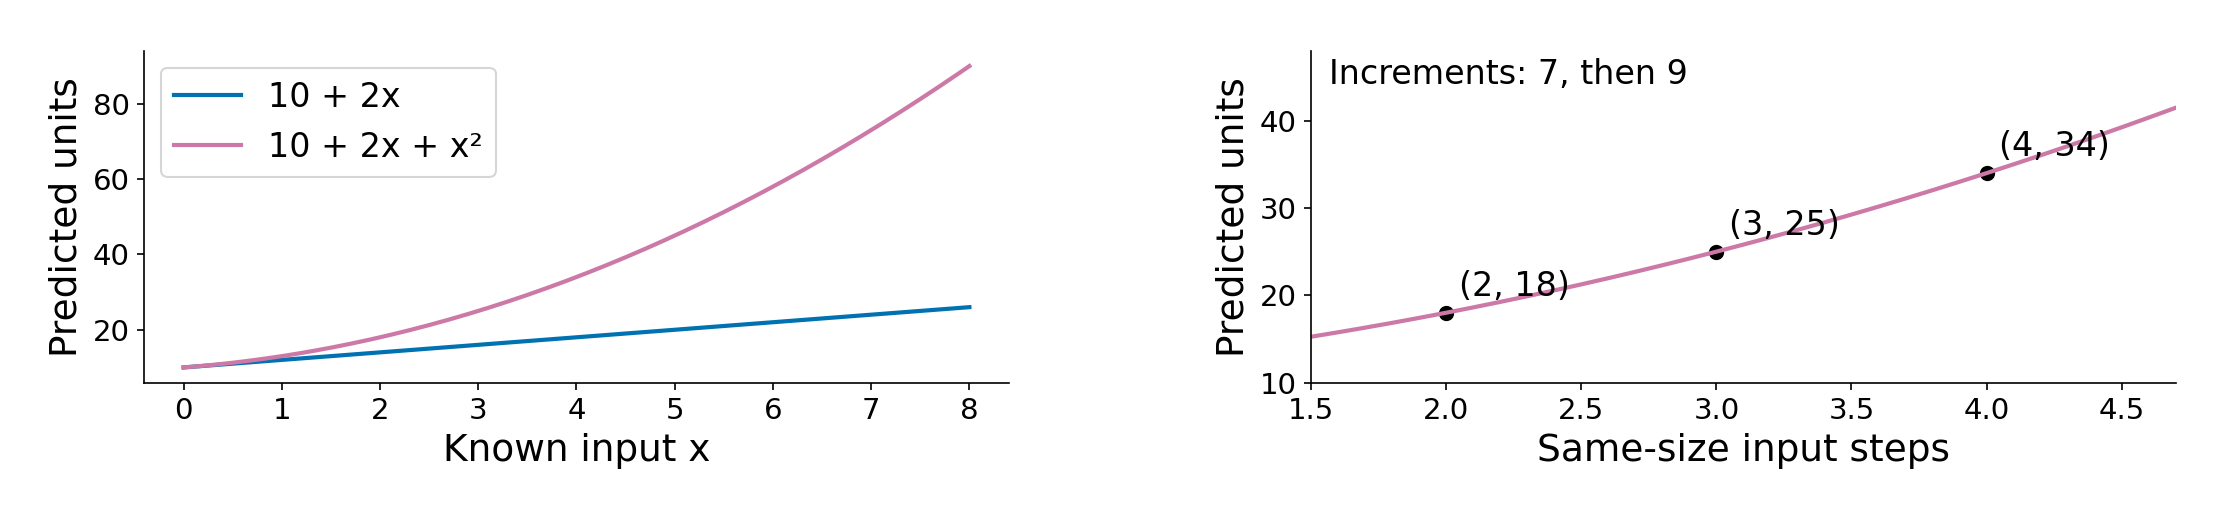

In [5]:
# Lecture code 4.1.4
(fig, aa) = canvas(2)
(a, b) = aa
a.plot(x, linear_rule, color=COL['Linear'], lw=2, label='10 + 2x')
a.plot(x, quadratic_rule, color=COL['Quadratic'], lw=2, label='10 + 2x + x²')
a.set(xlabel='Known input x', ylabel='Predicted units')
a.legend(loc='upper left')
b.plot(x, quadratic_rule, color=COL['Quadratic'], lw=2)
for xx in [2, 3, 4]:
    yy = 10 + 2 * xx + xx * xx
    b.scatter(xx, yy, color='black', s=40)
    b.annotate(f'({xx}, {yy})', (xx, yy), xytext=(6, 8), textcoords='offset points', fontsize=16)
b.set(xlim=(1.5, 4.7), ylim=(10, 48), xlabel='Same-size input steps', ylabel='Predicted units')
note(b, 'Increments: 7, then 9')
save(fig, 'ex01_curvature', 'Constant versus changing response; explicit 18,25,34 calculation', 'Constructed formula values', [2, 3])

### 4.1.5 — Read before running

Calculate or set `linear_queries` for this example. Subtract adjacent predictions. The quadratic increments are 7 and 9 for equal input steps; the linear increments remain 2. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [6]:
# Lecture code 4.1.5
linear_queries = np.array([[2, 3], [7, 8]])

### 4.1.6 — Read before running

Retain the calculated values of this example so they can be compared with the worked steps and exported tables.

In [7]:
# Lecture code 4.1.6
worked_values['linear'] = {'input_pairs': linear_queries.tolist(), 'prediction_pairs': (10 + 2 * linear_queries).tolist(), 'one_unit_increments': np.diff(10 + 2 * linear_queries, axis=1).ravel().tolist()}
display(worked_values['linear'])

{'input_pairs': [[2, 3], [7, 8]],
 'prediction_pairs': [[14, 16], [24, 26]],
 'one_unit_increments': [2, 2]}

### 4.1.7 — Read before running

Calculate or set `hand_x` for this example. Subtract adjacent predictions. The quadratic increments are 7 and 9 for equal input steps; the linear increments remain 2. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [8]:
# Lecture code 4.1.7
hand_x = np.array([2, 3, 4])

### 4.1.8 — Read before running

Calculate or set `hand_square` for this example. Subtract adjacent predictions. The quadratic increments are 7 and 9 for equal input steps; the linear increments remain 2. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [9]:
# Lecture code 4.1.8
hand_square = hand_x ** 2

### 4.1.9 — Read before running

Calculate or set `hand_prediction` for this example. Subtract adjacent predictions. The quadratic increments are 7 and 9 for equal input steps; the linear increments remain 2. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [10]:
# Lecture code 4.1.9
hand_prediction = 10 + 2 * hand_x + hand_square

### 4.1.10 — Read before running

Retain the calculated values of this example so they can be compared with the worked steps and exported tables.

In [11]:
# Lecture code 4.1.10
worked_values['polynomial'] = {'x': hand_x.tolist(), 'squares': hand_square.tolist(), 'prediction': hand_prediction.tolist(), 'increments': np.diff(hand_prediction).tolist()}
display(worked_values['polynomial'])

{'x': [2, 3, 4],
 'squares': [4, 9, 16],
 'prediction': [18, 25, 34],
 'increments': [7, 9]}

### 4.1.11 — Read before running

Draw the stated mechanism with labels. This is an explicitly constructed conceptual diagram, not evidence that one model forecasts better.

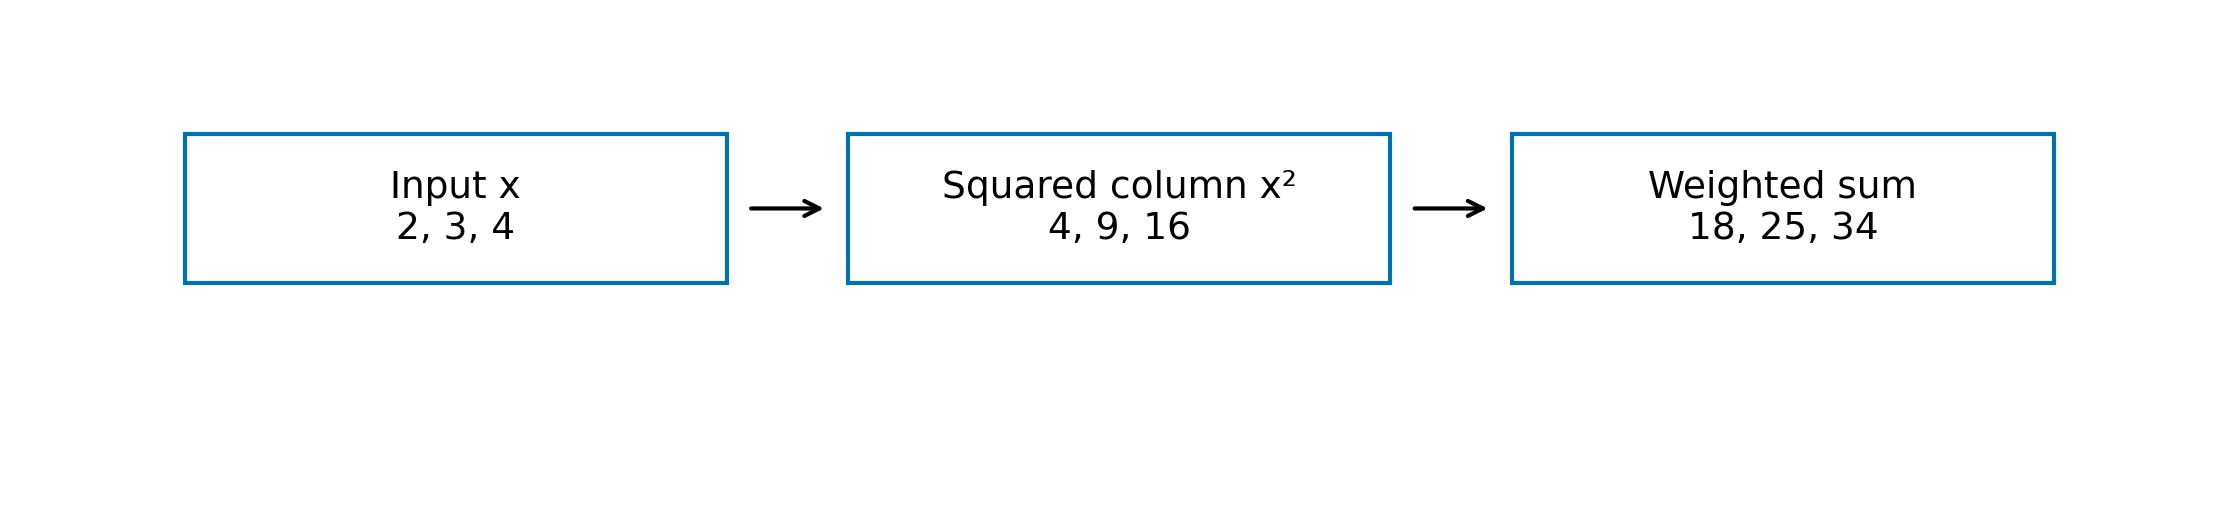

In [12]:
# Lecture code 4.1.11
flow('ex02_polynomial_columns', ['Input x\n' + ', '.join(map(str, hand_x)), 'Squared column x²\n' + ', '.join(map(str, hand_square)), 'Weighted sum\n' + ', '.join(map(str, hand_prediction))], 'Create a transformed input column before fitting weights', [4])

<a id="example-4-2"></a>
## 4.2 — Turn a known condition into an indicator

An indicator is one when its stated condition holds and zero otherwise.



**Work through the example**
1. Take a promotion schedule known at the forecast origin. The condition is whether promotion will be active; do not define it from the future sales outcome.
2. Set D=0 for inactive and D=1 for active. The two values encode the two permitted settings.
3. Check the displayed route: known schedule to indicator to a prediction input. The diagram is generated in code from those labels.
4. Keep a threshold, an indicator and a regime distinct: the cutoff defines a condition, the indicator encodes its truth, and the regime names the setting.

### 4.2.1 — Read before running

Calculate or set `promotion_schedule` for this example. Take a promotion schedule known at the forecast origin. The condition is whether promotion will be active; do not define it from the future sales outcome. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [13]:
# Lecture code 4.2.1
promotion_schedule = np.array([False, True, True, False])

### 4.2.2 — Read before running

Calculate or set `indicator_values` for this example. Set D=0 for inactive and D=1 for active. The two values encode the two permitted settings. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [14]:
# Lecture code 4.2.2
indicator_values = promotion_schedule.astype(int)

### 4.2.3 — Read before running

Retain the calculated values of this example so they can be compared with the worked steps and exported tables.

In [15]:
# Lecture code 4.2.3
worked_values['indicator'] = {'active': promotion_schedule.tolist(), 'D': indicator_values.tolist()}
display(worked_values['indicator'])

{'active': [False, True, True, False], 'D': [0, 1, 1, 0]}

### 4.2.4 — Read before running

Draw the stated mechanism with labels. This is an explicitly constructed conceptual diagram, not evidence that one model forecasts better.

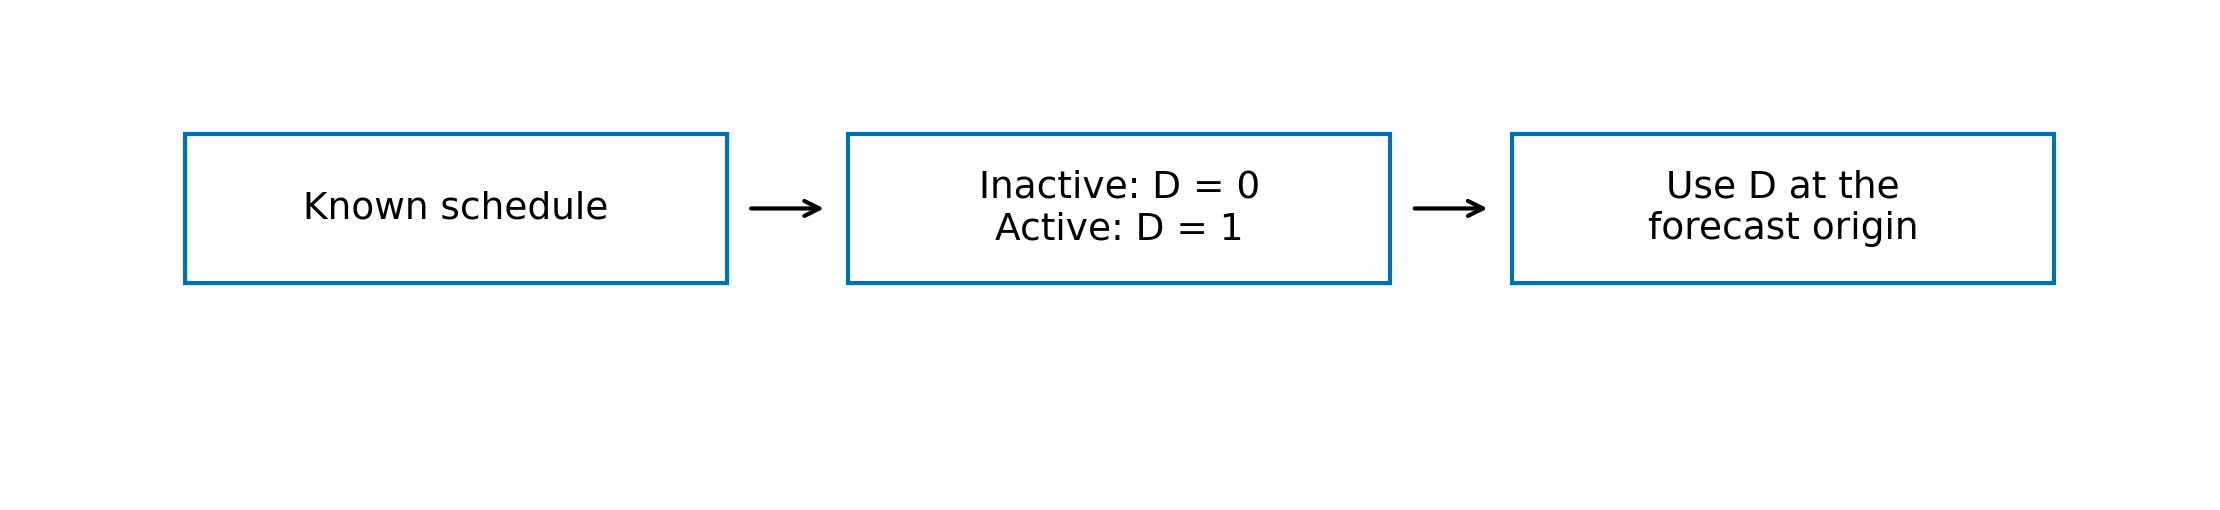

In [16]:
# Lecture code 4.2.4
flow('ex03_indicator', ['Known schedule', 'Inactive: D = 0\nActive: D = 1', 'Use D at the\nforecast origin'], 'The observed schedule becomes an indicator', [5])

<a id="example-4-3"></a>
## 4.3 — Calculate a promotion interaction

An interaction lets the response to x depend on another input.



**Work through the example**
1. Use the same constructed rule everywhere: predicted y = 10 + 2x + 5D + 3xD. The input x and promotion D must already be known.
2. Set x=2 and D=0. Both promotion terms vanish, leaving 10+4=14.
3. Set x=2 and D=1. Add the contributions 10, 4, 5 and 6 to obtain 25. Over the full x grid, the two rules are 10+2x and 15+5x.
4. Compare starting levels and slopes in the plotted lines. Switching D changes both in this example; it is not evidence of a causal promotion effect.

### 4.3.1 — Read before running

Plot the values or fitted rule computed above. Compare starting levels and slopes in the plotted lines. Switching D changes both in this example; it is not evidence of a causal promotion effect. The saved image is the same figure referenced by Example 4.3 in the notes and slides.

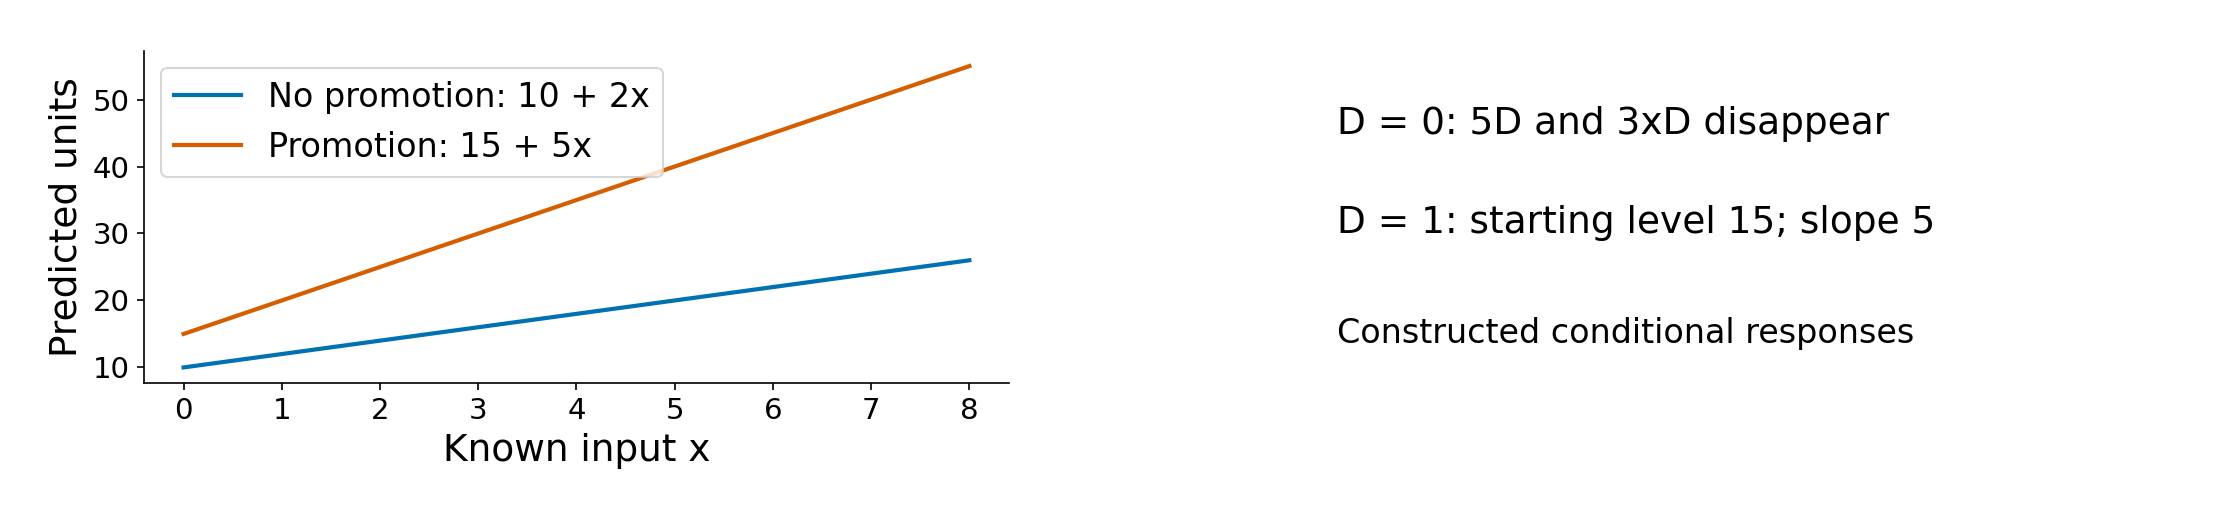

In [17]:
# Lecture code 4.3.1
(fig, aa) = canvas(2)
for (d, label, col) in [(0, 'No promotion: 10 + 2x', COL['Linear']), (1, 'Promotion: 15 + 5x', COL['Tree'])]:
    aa[0].plot(x, 10 + 2 * x + 5 * d + 3 * x * d, color=col, lw=2, label=label)
aa[0].set(xlabel='Known input x', ylabel='Predicted units')
aa[0].legend(loc='upper left')
aa[1].axis('off')
aa[1].text(0.03, 0.75, 'D = 0: 5D and 3xD disappear', fontsize=18)
aa[1].text(0.03, 0.45, 'D = 1: starting level 15; slope 5', fontsize=18)
aa[1].text(0.03, 0.12, 'Constructed conditional responses', fontsize=16)
save(fig, 'ex04_interaction', 'Switch the indicator and compare two responses', 'Constructed formula values', [6])

### 4.3.2 — Read before running

Retain the calculated values of this example so they can be compared with the worked steps and exported tables.

In [18]:
# Lecture code 4.3.2
worked_values['interaction'] = {'x': 2, 'D0_prediction': float(10 + 2 * 2), 'D1_prediction': float(10 + 2 * 2 + 5 + 3 * 2)}
display(worked_values['interaction'])

{'x': 2, 'D0_prediction': 14.0, 'D1_prediction': 25.0}

<a id="example-4-4"></a>
## 4.4 — Read roots, branches, leaves and depth

A regression tree routes a known input through questions to a stored numerical mean.

A node is a location in the tree. The root is the starting node; a split asks a question, a branch follows its answer, and a leaf is a terminal group. Depth counts split questions along a path.

**Work through the example**
1. Fit the eight traffic/sales pairs used in Example 4.5. The root contains eight observations and asks whether yesterday's traffic is at most 50.
2. Follow Yes or No to the two leaves. A split is the question; branches are its answers; leaves are the terminal prediction groups.
3. Fit a second tree with maximum depth two on the same pairs. Count splits along a case's path: root depth zero, first answer depth one, second answer depth two.
4. Read the plotted fitted structure rather than counting leaves as depth. In the depth-two tree, the four stored means are 22, 30, 62 and 70.

### 4.4.1 — Read before running

Calculate or set `traffic` for this example. Fit the eight traffic/sales pairs used in Example 4.5. The root contains eight observations and asks whether yesterday's traffic is at most 50. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [19]:
# Lecture code 4.4.1
traffic = np.array([10, 20, 30, 40, 60, 70, 80, 90])

### 4.4.2 — Read before running

Calculate or set `sales` for this example. Follow Yes or No to the two leaves. A split is the question; branches are its answers; leaves are the terminal prediction groups. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [20]:
# Lecture code 4.4.2
sales = np.array([20, 24, 28, 32, 60, 64, 68, 72])

### 4.4.3 — Read before running

Calculate or set `stump` for this example. Fit a second tree with maximum depth two on the same pairs. Count splits along a case's path: root depth zero, first answer depth one, second answer depth two. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [21]:
# Lecture code 4.4.3
stump = DecisionTreeRegressor(max_depth=1, random_state=417).fit(traffic[:, None], sales)

### 4.4.4 — Read before running

Calculate or set `threshold` for this example. Fit a second tree with maximum depth two on the same pairs. Count splits along a case's path: root depth zero, first answer depth one, second answer depth two. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [22]:
# Lecture code 4.4.4
threshold = float(stump.tree_.threshold[0])

### 4.4.5 — Read before running

Calculate or set `leaf_preds` for this example. Fit a second tree with maximum depth two on the same pairs. Count splits along a case's path: root depth zero, first answer depth one, second answer depth two. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [23]:
# Lecture code 4.4.5
leaf_preds = stump.predict([[35], [75]])

### 4.4.6 — Read before running

Check the stated mathematical or timing property for this worked example. A failed check is a reason to inspect the inputs or calculation.

In [24]:
# Lecture code 4.4.6
assert threshold == 50 and np.allclose(leaf_preds, [26, 66])

### 4.4.7 — Read before running

Plot the values or fitted rule computed above. Read the plotted fitted structure rather than counting leaves as depth. In the depth-two tree, the four stored means are 22, 30, 62 and 70. The saved image is the same figure referenced by Example 4.4 in the notes and slides.

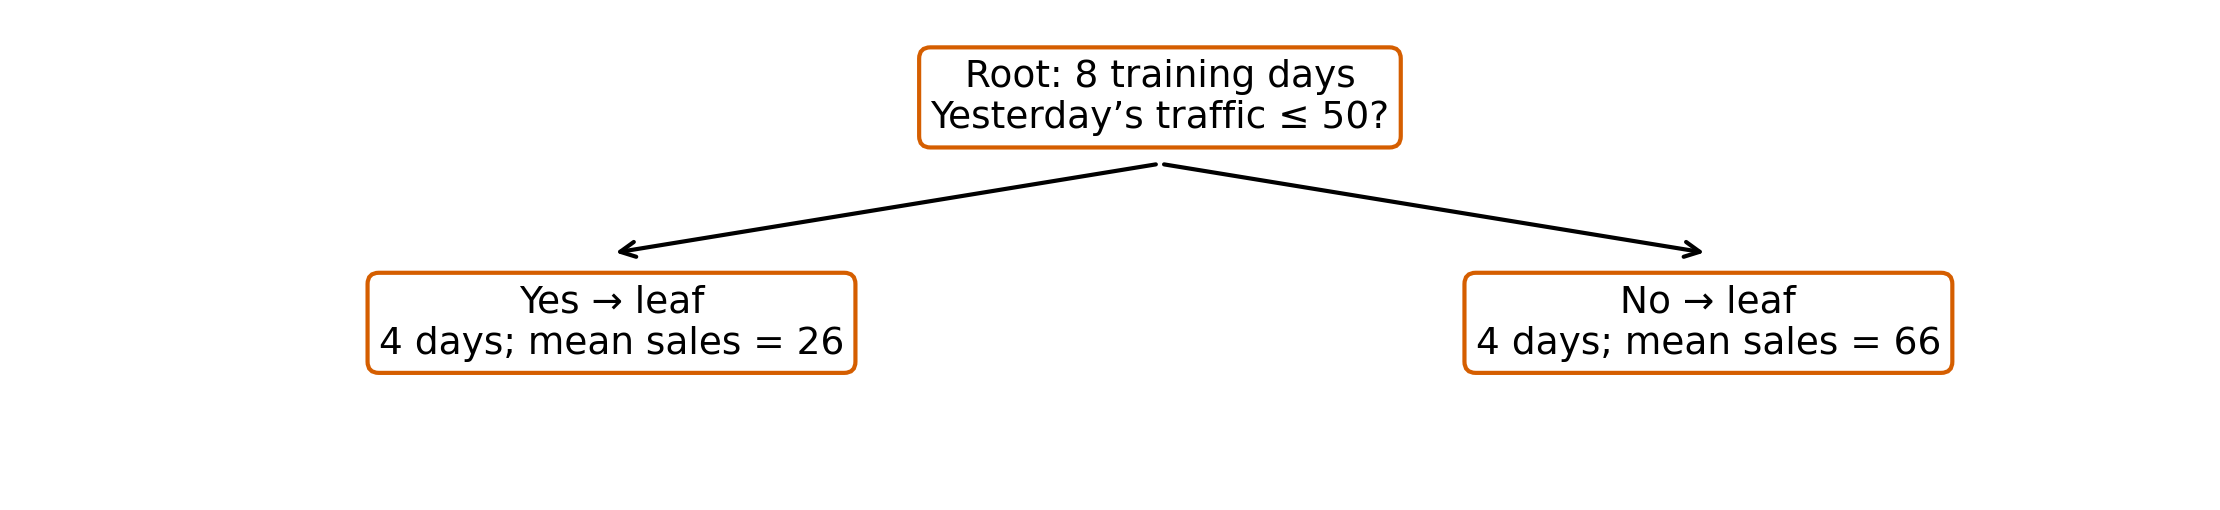

In [25]:
# Lecture code 4.4.7
(fig, aa) = canvas()
ax = aa[0]
ax.axis('off')
for (xy, label) in [((0.5, 0.86), 'Root: 8 training days\nYesterday’s traffic ≤ 50?'), ((0.23, 0.18), 'Yes → leaf\n4 days; mean sales = 26'), ((0.77, 0.18), 'No → leaf\n4 days; mean sales = 66')]:
    ax.text(*xy, label, ha='center', va='center', bbox=dict(boxstyle='round', facecolor='white', edgecolor=COL['Tree'], lw=2), fontsize=18)
for xx in [0.23, 0.77]:
    ax.annotate('', xy=(xx, 0.39), xytext=(0.5, 0.66), arrowprops=dict(arrowstyle='->', lw=2, color='black'))
save(fig, 'ex05_tree_parts', 'Actual fitted root, branches and mean-valued leaves', 'Eight constructed training days; sklearn fitted tree', [7])

### 4.4.8 — Read before running

Plot the values or fitted rule computed above. Read the plotted fitted structure rather than counting leaves as depth. In the depth-two tree, the four stored means are 22, 30, 62 and 70. The saved image is the same figure referenced by Example 4.4 in the notes and slides.

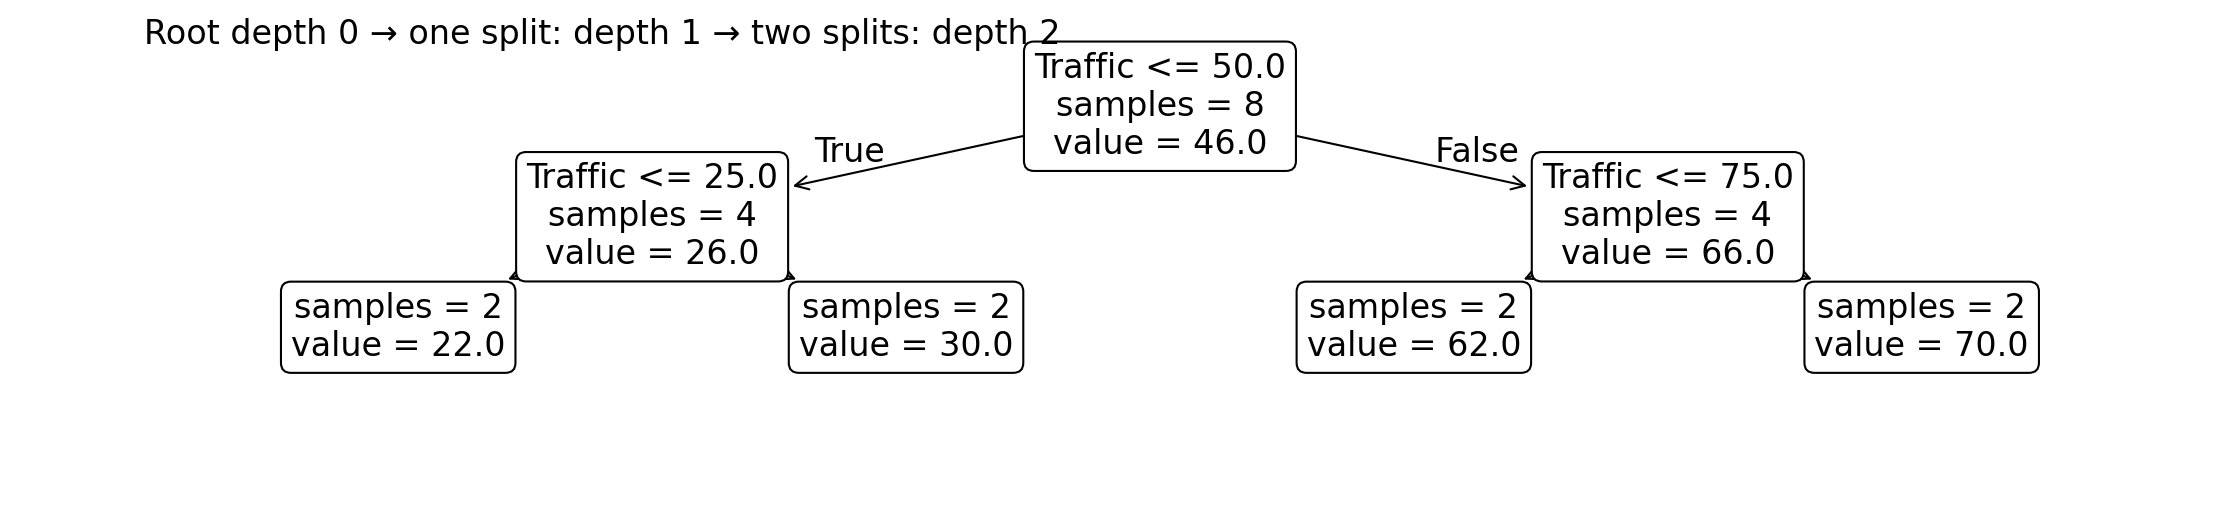

In [26]:
# Lecture code 4.4.8
(fig, aa) = canvas()
plot_tree(DecisionTreeRegressor(max_depth=2, random_state=417).fit(traffic[:, None], sales), ax=aa[0], feature_names=['Traffic'], impurity=False, filled=False, rounded=True, fontsize=16)
fig.text(0.065, 0.965, 'Root depth 0 → one split: depth 1 → two splits: depth 2', va='top', fontsize=16)
save(fig, 'ex06_tree_depth', 'Depth is path length, not the number of leaves', 'Same eight constructed days; depth-two fitted tree', [8])

<a id="example-4-5"></a>
## 4.5 — Compute leaf means and route new cases

A squared-error regression leaf predicts its training outcome mean.



**Work through the example**
1. Pair traffic [10,20,30,40,60,70,80,90] with sales [20,24,28,32,60,64,68,72]. The input precedes the sales target.
2. Split traffic at 50. Average the four left outcomes to get 26 and the four right outcomes to get 66.
3. Route the new input 35 to the left and 75 to the right. The computed predictions are 26 and 66; the unknown new outcomes are never used in routing.
4. Read the fitted graph as two constant regions, not a sloping interpolation within each leaf.

### 4.5.1 — Read before running

Plot the values or fitted rule computed above. Read the fitted graph as two constant regions, not a sloping interpolation within each leaf. The saved image is the same figure referenced by Example 4.5 in the notes and slides.

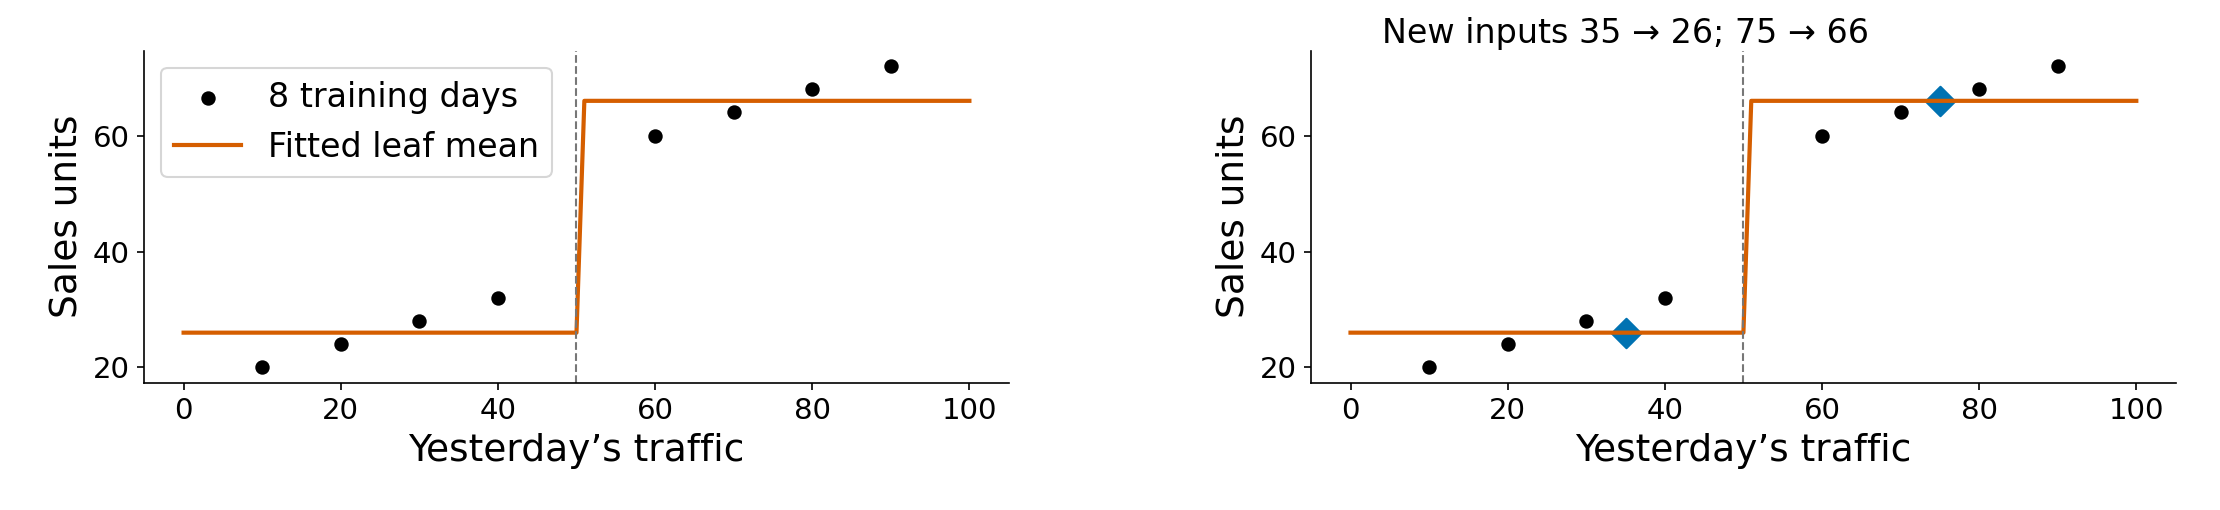

In [27]:
# Lecture code 4.5.1
(fig, aa) = canvas(2)
for ax in aa:
    ax.scatter(traffic, sales, color='black', s=35, label='8 training days')
    grid = np.arange(0, 101)
    ax.plot(grid, stump.predict(grid[:, None]), color=COL['Tree'], lw=2, label='Fitted leaf mean')
    ax.axvline(50, color='#777777', ls='--', lw=1)
    ax.set(xlabel='Yesterday’s traffic', ylabel='Sales units')
aa[0].legend(loc='upper left')
aa[1].scatter([35, 75], leaf_preds, s=100, marker='D', color=COL['Linear'])
aa[1].text(4, 76, 'New inputs 35 → 26; 75 → 66', fontsize=16)
save(fig, 'ex07_leaf_predictions', 'Route two unseen cases to stored means', 'Eight constructed training days; fitted predictions', [9])

<a id="example-4-6"></a>
## 4.6 — Choose a split by its immediate training gain

Greedy fitting chooses the best current training step, not an entire future tree.



**Work through the example**
1. Keep the eight pairs fixed. Without splitting, the mean sales value is 46; squared distances from that mean sum to 3360.
2. At cutoff 50, the two within-leaf squared-error sums are 80 and 80, giving total 160.
3. Subtract 160 from 3360: the immediate training reduction is 3200. The candidate-cutoff table is computed for all seven separating cutoffs.
4. Find the minimum of the plotted candidate scores. This explains the fitted cutoff 50 but does not measure validation improvement.

### 4.6.1 — Read before running

Calculate or set `base_sse` for this example. Keep the eight pairs fixed. Without splitting, the mean sales value is 46; squared distances from that mean sum to 3360. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [28]:
# Lecture code 4.6.1
base_sse = float(((sales - sales.mean()) ** 2).sum())

### 4.6.2 — Read before running

Calculate or set `cuts` for this example. At cutoff 50, the two within-leaf squared-error sums are 80 and 80, giving total 160. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [29]:
# Lecture code 4.6.2
cuts = (traffic[:-1] + traffic[1:]) / 2

### 4.6.3 — Read before running

Prepare storage for the candidate cutoff scores; each entry will measure training squared error for the same observations.

In [30]:
# Lecture code 4.6.3
scores = []

### 4.6.4 — Read before running

For each candidate cutoff, form the two training groups, compute their own means and add the two within-group squared-error sums.

In [31]:
# Lecture code 4.6.4
for cut in cuts:
    left = sales[traffic <= cut]
    right = sales[traffic > cut]
    scores.append(float(((left - left.mean()) ** 2).sum() + ((right - right.mean()) ** 2).sum()))

### 4.6.5 — Read before running

Check the stated mathematical or timing property for this worked example. A failed check is a reason to inspect the inputs or calculation.

In [32]:
# Lecture code 4.6.5
assert base_sse == 3360 and min(scores) == 160

### 4.6.6 — Read before running

Put the calculated values in a labeled table. The table is an output of the current run, not a manually typed performance claim.

In [33]:
# Lecture code 4.6.6
pd.DataFrame({'cutoff': cuts, 'training_SSE': scores}).to_csv(OUT / 'split_candidates.csv', index=False)

### 4.6.7 — Read before running

Retain the calculated values of this example so they can be compared with the worked steps and exported tables.

In [34]:
# Lecture code 4.6.7
worked_values['stump'] = {'traffic': traffic.tolist(), 'sales': sales.tolist(), 'cutoff': threshold, 'leaf_predictions': leaf_preds.tolist(), 'unsplit_mean': float(sales.mean()), 'unsplit_SSE': base_sse, 'split_SSE': min(scores), 'reduction': base_sse - min(scores)}
display(worked_values['stump'])

{'traffic': [10, 20, 30, 40, 60, 70, 80, 90],
 'sales': [20, 24, 28, 32, 60, 64, 68, 72],
 'cutoff': 50.0,
 'leaf_predictions': [26.0, 66.0],
 'unsplit_mean': 46.0,
 'unsplit_SSE': 3360.0,
 'split_SSE': 160.0,
 'reduction': 3200.0}

### 4.6.8 — Read before running

Plot the values or fitted rule computed above. Find the minimum of the plotted candidate scores. This explains the fitted cutoff 50 but does not measure validation improvement. The saved image is the same figure referenced by Example 4.6 in the notes and slides.

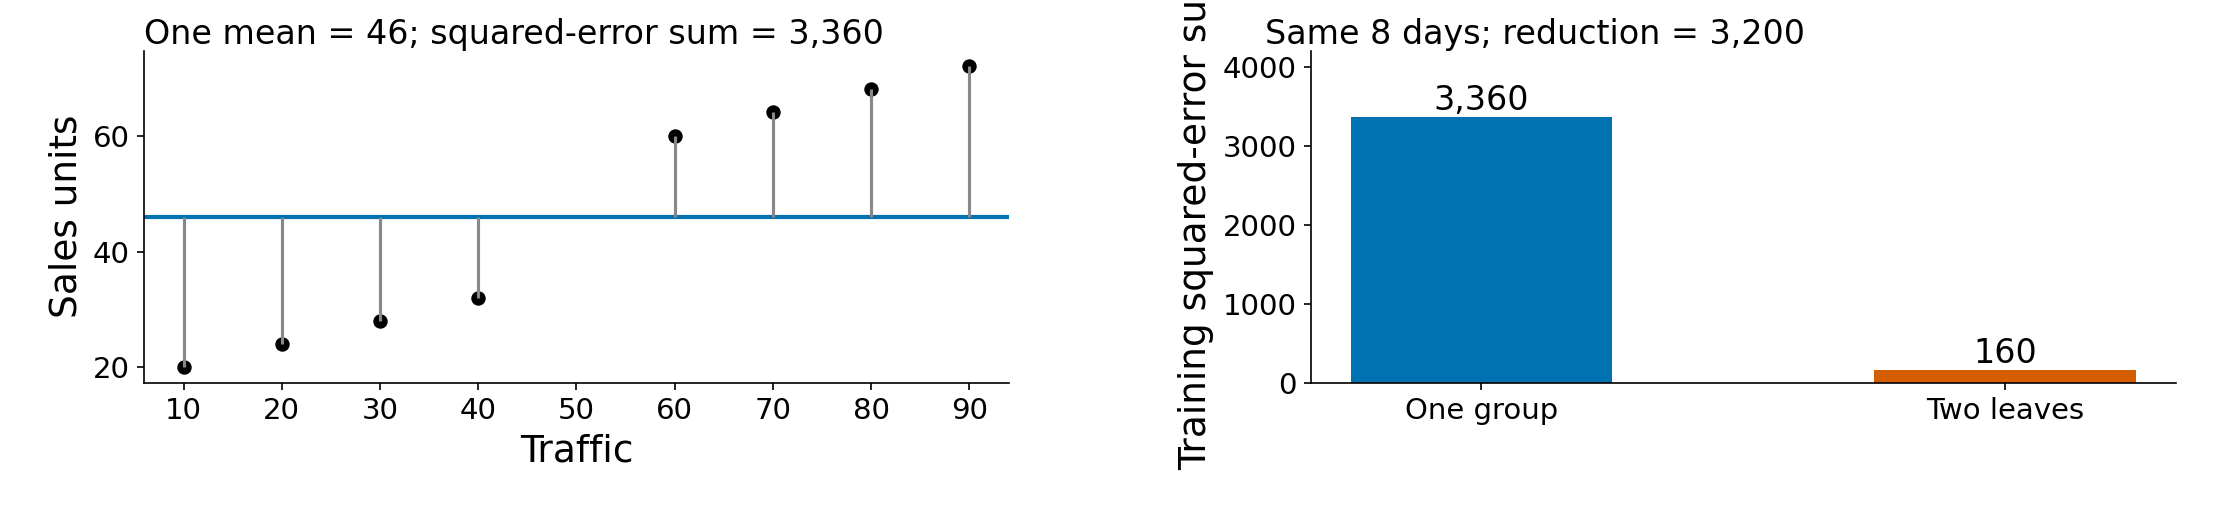

In [35]:
# Lecture code 4.6.8
(fig, aa) = canvas(2)
aa[0].scatter(traffic, sales, color='black', s=35)
aa[0].axhline(sales.mean(), color=COL['Linear'], lw=2)
aa[0].vlines(traffic, sales, sales.mean(), color='#888888')
aa[0].set(xlabel='Traffic', ylabel='Sales units')
fig.text(0.065, 0.965, 'One mean = 46; squared-error sum = 3,360', va='top', fontsize=16)
aa[1].bar(['One group', 'Two leaves'], [base_sse, min(scores)], color=[COL['Linear'], COL['Tree']], width=0.5)
for (j, v) in enumerate([base_sse, min(scores)]):
    aa[1].text(j, v + 90, f'{v:,.0f}', ha='center', fontsize=16)
aa[1].set(ylabel='Training squared-error sum', ylim=(0, 4200))
fig.text(0.57, 0.965, 'Same 8 days; reduction = 3,200', va='top', fontsize=16)
save(fig, 'ex08_split_gain', 'Calculate the training gain without claiming future improvement', 'Same eight constructed observations', [10])

### 4.6.9 — Read before running

Plot the values or fitted rule computed above. Find the minimum of the plotted candidate scores. This explains the fitted cutoff 50 but does not measure validation improvement. The saved image is the same figure referenced by Example 4.6 in the notes and slides.

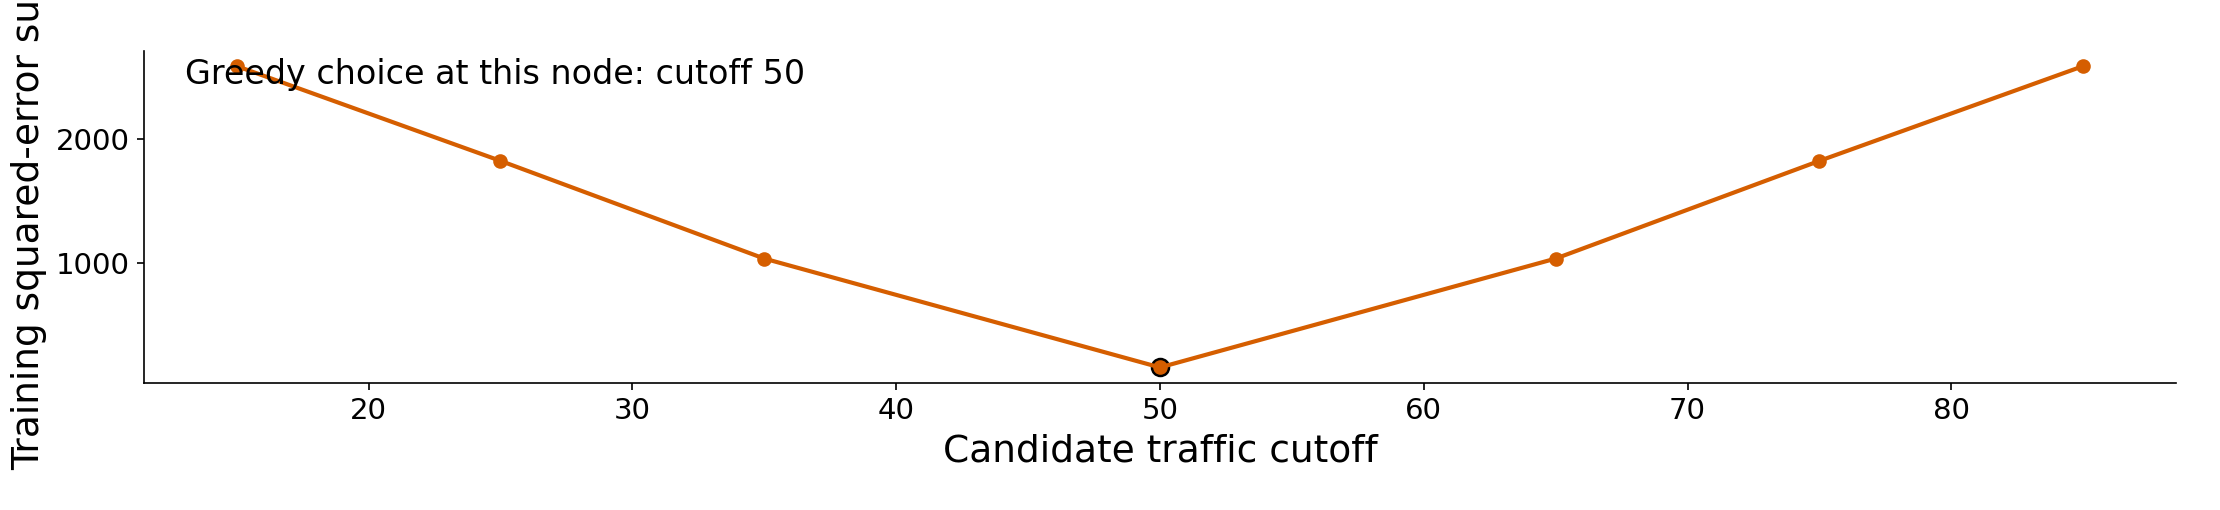

In [36]:
# Lecture code 4.6.9
(fig, aa) = canvas()
aa[0].plot(cuts, scores, 'o-', color=COL['Tree'], lw=2)
aa[0].scatter([50], [160], color='black', s=70)
aa[0].set(xlabel='Candidate traffic cutoff', ylabel='Training squared-error sum')
note(aa[0], 'Greedy choice at this node: cutoff 50')
save(fig, 'ex09_split_search', 'Compare actual permitted thresholds', 'Eight constructed observations, all seven separating cutoffs', [11])

<a id="example-4-7"></a>
## 4.7 — Connect rectangles to a conditional tree

One-input splits divide two-input space into rectangular prediction regions.



**Work through the example**
1. Construct twelve cases from traffic [10,20,40,60,80,90] crossed with promotion D=0 or 1. This is a different labeled toy dataset from Example 4.3.
2. Assign sales 20 when traffic is at most 50. Above 50, assign 30 without promotion and 50 with promotion.
3. Fit the depth-two tree. It first separates traffic and then asks about promotion only inside the high-traffic branch.
4. Predict [35,0], [35,1], [75,0] and [75,1]. The outputs 20,20,30,50 connect the rectangular colors to the tree's conditional routes.

### 4.7.1 — Read before running

Calculate or set `grid_t` for this example. Construct twelve cases from traffic [10,20,40,60,80,90] crossed with promotion D=0 or 1. This is a different labeled toy dataset from Example 4.3. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [37]:
# Lecture code 4.7.1
grid_t = np.repeat([10, 20, 40, 60, 80, 90], 2)

### 4.7.2 — Read before running

Calculate or set `promo` for this example. Assign sales 20 when traffic is at most 50. Above 50, assign 30 without promotion and 50 with promotion. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [38]:
# Lecture code 4.7.2
promo = np.tile([0, 1], 6)

### 4.7.3 — Read before running

Calculate or set `z` for this example. Fit the depth-two tree. It first separates traffic and then asks about promotion only inside the high-traffic branch. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [39]:
# Lecture code 4.7.3
z = 20 + 10 * (grid_t > 50) + 20 * (grid_t > 50) * promo

### 4.7.4 — Read before running

Calculate or set `xy` for this example. Fit the depth-two tree. It first separates traffic and then asks about promotion only inside the high-traffic branch. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [40]:
# Lecture code 4.7.4
xy = np.column_stack([grid_t, promo])

### 4.7.5 — Read before running

Calculate or set `tree2` for this example. Fit the depth-two tree. It first separates traffic and then asks about promotion only inside the high-traffic branch. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [41]:
# Lecture code 4.7.5
tree2 = DecisionTreeRegressor(max_depth=2, random_state=417).fit(xy, z)

### 4.7.6 — Read before running

Calculate or set `(g1, g2)` for this example. Fit the depth-two tree. It first separates traffic and then asks about promotion only inside the high-traffic branch. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [42]:
# Lecture code 4.7.6
(g1, g2) = np.meshgrid(np.linspace(0, 100, 251), np.linspace(-0.2, 1.2, 141))

### 4.7.7 — Read before running

Evaluate the fitted two-input tree over a coordinate grid. Its repeated leaf values create the rectangular prediction regions.

In [43]:
# Lecture code 4.7.7
surface = tree2.predict(np.column_stack([g1.ravel(), g2.ravel()])).reshape(g1.shape)

### 4.7.8 — Read before running

Plot the values or fitted rule computed above. Predict [35,0], [35,1], [75,0] and [75,1]. The outputs 20,20,30,50 connect the rectangular colors to the tree's conditional routes. The saved image is the same figure referenced by Example 4.7 in the notes and slides.

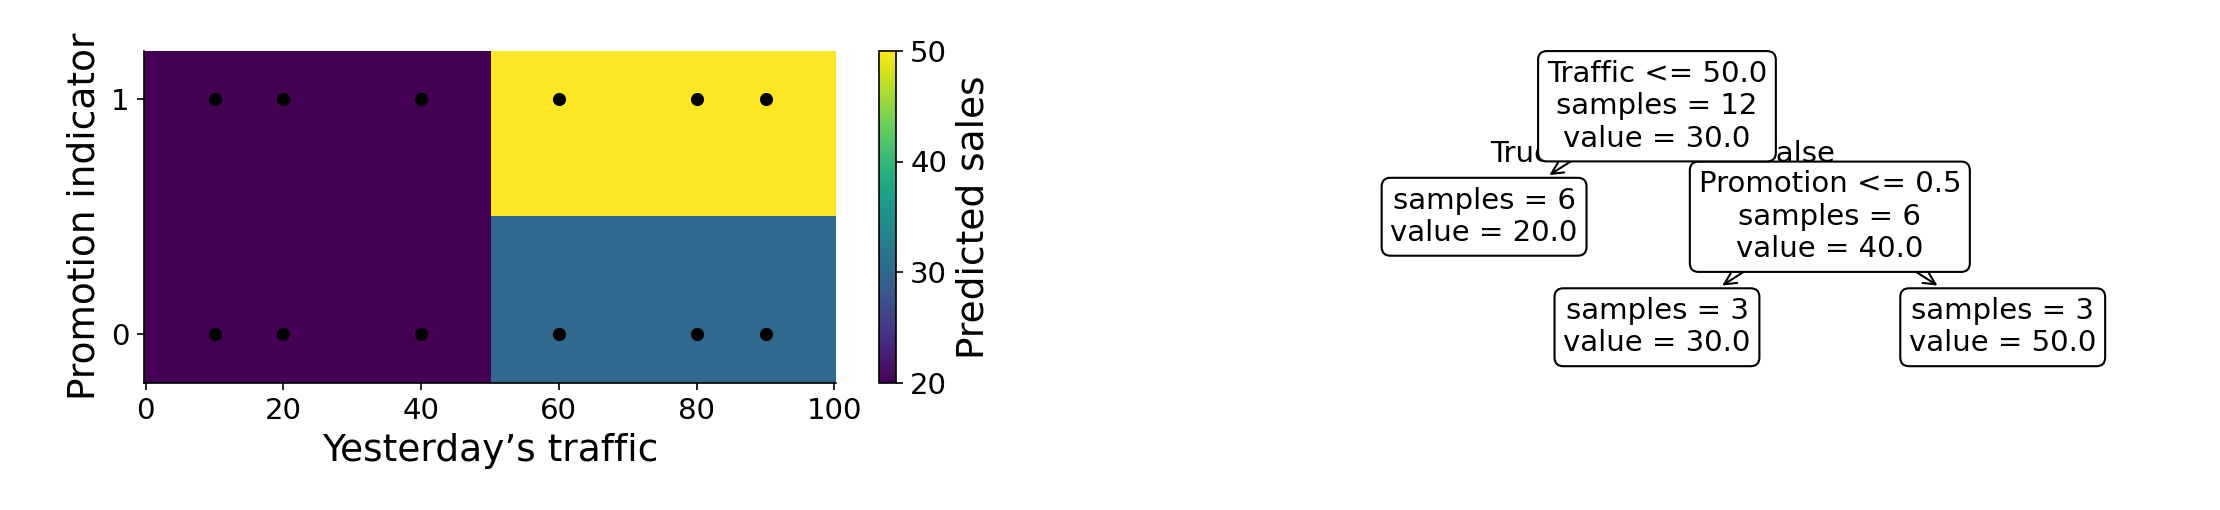

In [44]:
# Lecture code 4.7.8
(fig, aa) = canvas(2)
mesh = aa[0].pcolormesh(g1, g2, surface, cmap='viridis', shading='nearest', vmin=20, vmax=50)
aa[0].scatter(grid_t, promo, color='black', s=28)
aa[0].set(xlabel='Yesterday’s traffic', ylabel='Promotion indicator', yticks=[0, 1])
fig.colorbar(mesh, ax=aa[0], label='Predicted sales')
plot_tree(tree2, ax=aa[1], feature_names=['Traffic', 'Promotion'], impurity=False, rounded=True, fontsize=14)
worked_values['partition'] = {'cases': [[35, 0], [35, 1], [75, 0], [75, 1]], 'predictions': tree2.predict([[35, 0], [35, 1], [75, 0], [75, 1]]).tolist()}
save(fig, 'ex10_rectangles', 'Connect input-space regions to the fitted conditional routes', '12 constructed input pairs; known promotion, sales 20/30/50', [12, 13])

<a id="example-4-8"></a>
## 4.8 — Prepare the classroom demand example

Simulation creates artificial observations from stated rules; these are not market data.



**Work through the example**
1. Load the local business_demand.csv copied from the existing classroom package. It contains 180 simulated daily observations, source seed 417.
2. Create demand one day and two days earlier. Removing the first two unavailable lags leaves 178 usable rows.
3. Preserve date order. Use the first 124 rows for training, the next 27 for validation and the last 27 for final testing.
4. Read the date-series graph and the shaded periods. Both predictors are observed before the current demand target; no download fallback changes the data source.

### 4.8.1 — Read before running

Load the named local snapshot, parse its dates and put dates in order. Check the data source before interpreting any model score.

In [45]:
# Lecture code 4.8.1
data = pd.read_csv(HERE / 'business_demand.csv', parse_dates=['date']).set_index('date').sort_index()

### 4.8.2 — Read before running

Check the stated mathematical or timing property for this worked example. A failed check is a reason to inspect the inputs or calculation.

In [46]:
# Lecture code 4.8.2
assert data.index.is_unique

### 4.8.3 — Read before running

Construct the one-day lag. At the target date, this input contains an earlier observed outcome, not the current unknown target.

In [47]:
# Lecture code 4.8.3
data['lag_demand'] = data.demand.shift(1)

### 4.8.4 — Read before running

Construct the two-day lag. It supplies a second earlier observation rather than a future value.

In [48]:
# Lecture code 4.8.4
data['lag_demand_2'] = data.demand.shift(2)

### 4.8.5 — Read before running

Keep cases whose required lags exist. The first two unavailable lags explain the change from 180 raw days to 178 usable rows.

In [49]:
# Lecture code 4.8.5
frame = data.dropna().copy()

### 4.8.6 — Read before running

Calculate or set `features` for this example. Preserve date order. Use the first 124 rows for training, the next 27 for validation and the last 27 for final testing. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [50]:
# Lecture code 4.8.6
features = ['lag_demand', 'lag_demand_2']

### 4.8.7 — Read before running

Calculate or set `a` for this example. Preserve date order. Use the first 124 rows for training, the next 27 for validation and the last 27 for final testing. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [51]:
# Lecture code 4.8.7
a = int(len(frame) * 0.7)

### 4.8.8 — Read before running

Calculate or set `b` for this example. Preserve date order. Use the first 124 rows for training, the next 27 for validation and the last 27 for final testing. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [52]:
# Lecture code 4.8.8
b = int(len(frame) * 0.85)

### 4.8.9 — Read before running

Calculate or set `(train, val, test)` for this example. Preserve date order. Use the first 124 rows for training, the next 27 for validation and the last 27 for final testing. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [53]:
# Lecture code 4.8.9
(train, val, test) = (frame.iloc[:a], frame.iloc[a:b], frame.iloc[b:])

### 4.8.10 — Read before running

Calculate or set `(X, y)` for this example. Preserve date order. Use the first 124 rows for training, the next 27 for validation and the last 27 for final testing. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [54]:
# Lecture code 4.8.10
(X, y) = (train[features], train.demand)

### 4.8.11 — Read before running

Check the stated mathematical or timing property for this worked example. A failed check is a reason to inspect the inputs or calculation.

In [55]:
# Lecture code 4.8.11
assert train.index.max() < val.index.min() < test.index.min()

### 4.8.12 — Read before running

Plot the values or fitted rule computed above. Read the date-series graph and the shaded periods. Both predictors are observed before the current demand target; no download fallback changes the data source. The saved image is the same figure referenced by Example 4.8 in the notes and slides.

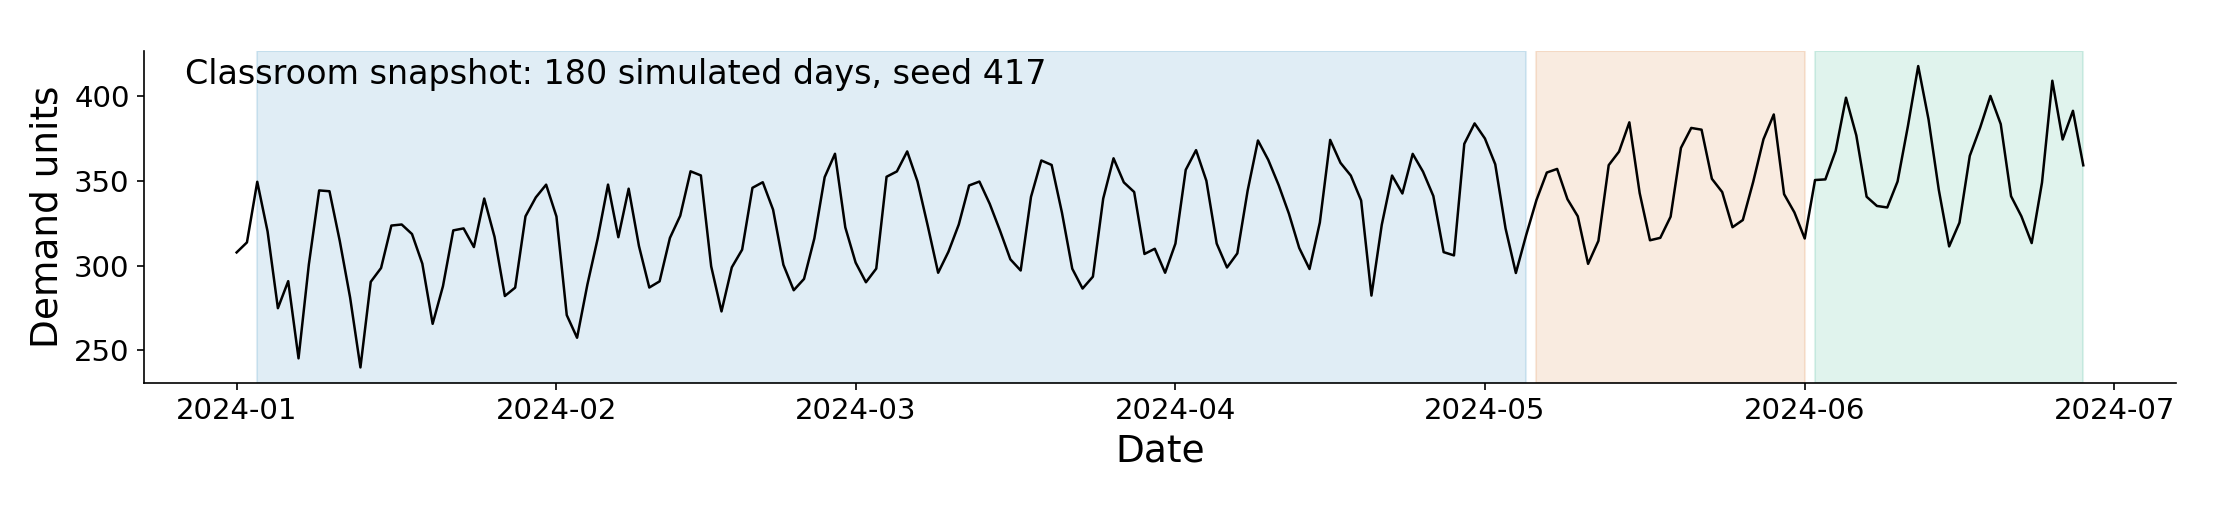

In [56]:
# Lecture code 4.8.12
(fig, aa) = canvas()
aa[0].plot(data.index, data.demand, color='black', lw=1.2)
aa[0].axvspan(train.index.min(), train.index.max(), color=COL['Linear'], alpha=0.12)
aa[0].axvspan(val.index.min(), val.index.max(), color=COL['Tree'], alpha=0.12)
aa[0].axvspan(test.index.min(), test.index.max(), color=COL['Forest'], alpha=0.12)
aa[0].set(xlabel='Date', ylabel='Demand units')
aa[0].tick_params(axis='x', labelsize=14)
note(aa[0], 'Classroom snapshot: 180 simulated days, seed 417')
save(fig, 'ex26_classroom_data', 'Show the actual classroom dataset and evaluation periods', 'Local classroom synthetic business_demand.csv', [31])

<a id="example-4-9"></a>
## 4.9 — Vary one tree control at a time

Depth, leaf size and pruning constrain different aspects of a tree.

Minimum leaf size is the fewest training observations allowed in a final group. Pruning removes branches from a fitted tree. Both restrict tree complexity.

**Work through the example**
1. In the left panel, vary maximum depth from one to eight with minimum leaf size held at two. Compute training and validation RMSE on fixed dates.
2. In the middle panel, vary minimum leaf size across 1,2,4,8,16 while maximum depth is eight.
3. In the right panel, vary pruning strength across 0,5,20,80,200, with minimum leaf size two. Count the remaining leaves.
4. These conditional comparisons explain the controls. They do not replace the joint depth/leaf-size search in Example 4.10.

### 4.9.1 — Read before running

Calculate or set `depths` for this example. In the left panel, vary maximum depth from one to eight with minimum leaf size held at two. Compute training and validation RMSE on fixed dates. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [57]:
# Lecture code 4.9.1
depths = list(range(1, 9))

### 4.9.2 — Read before running

Calculate or set `trees` for this example. In the middle panel, vary minimum leaf size across 1,2,4,8,16 while maximum depth is eight. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [58]:
# Lecture code 4.9.2
trees = {d: DecisionTreeRegressor(max_depth=d, min_samples_leaf=2, random_state=417).fit(X, y) for d in depths}

### 4.9.3 — Read before running

Calculate or set `depth_train` for this example. In the right panel, vary pruning strength across 0,5,20,80,200, with minimum leaf size two. Count the remaining leaves. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [59]:
# Lecture code 4.9.3
depth_train = [rmse(y, m.predict(X)) for m in trees.values()]

### 4.9.4 — Read before running

Calculate or set `depth_val` for this example. In the right panel, vary pruning strength across 0,5,20,80,200, with minimum leaf size two. Count the remaining leaves. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [60]:
# Lecture code 4.9.4
depth_val = [rmse(val.demand, m.predict(val[features])) for m in trees.values()]

### 4.9.5 — Read before running

Calculate or set `best_depth` for this example. In the right panel, vary pruning strength across 0,5,20,80,200, with minimum leaf size two. Count the remaining leaves. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [61]:
# Lecture code 4.9.5
best_depth = depths[int(np.argmin(depth_val))]

### 4.9.6 — Read before running

Calculate or set `leaves` for this example. In the right panel, vary pruning strength across 0,5,20,80,200, with minimum leaf size two. Count the remaining leaves. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [62]:
# Lecture code 4.9.6
leaves = [1, 2, 4, 8, 16]

### 4.9.7 — Read before running

Collect the fixed candidate procedures. This does not select the winner from final-test outcomes.

In [63]:
# Lecture code 4.9.7
leaf_models = [DecisionTreeRegressor(max_depth=8, min_samples_leaf=l, random_state=417).fit(X, y) for l in leaves]

### 4.9.8 — Read before running

Calculate or set `prunes` for this example. In the right panel, vary pruning strength across 0,5,20,80,200, with minimum leaf size two. Count the remaining leaves. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [64]:
# Lecture code 4.9.8
prunes = [0, 5, 20, 80, 200]

### 4.9.9 — Read before running

Calculate or set `pruned` for this example. In the right panel, vary pruning strength across 0,5,20,80,200, with minimum leaf size two. Count the remaining leaves. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [65]:
# Lecture code 4.9.9
pruned = [DecisionTreeRegressor(ccp_alpha=v, min_samples_leaf=2, random_state=417).fit(X, y) for v in prunes]

### 4.9.10 — Read before running

Plot the values or fitted rule computed above. These conditional comparisons explain the controls. They do not replace the joint depth/leaf-size search in Example 4.10. The saved image is the same figure referenced by Example 4.9 in the notes and slides.

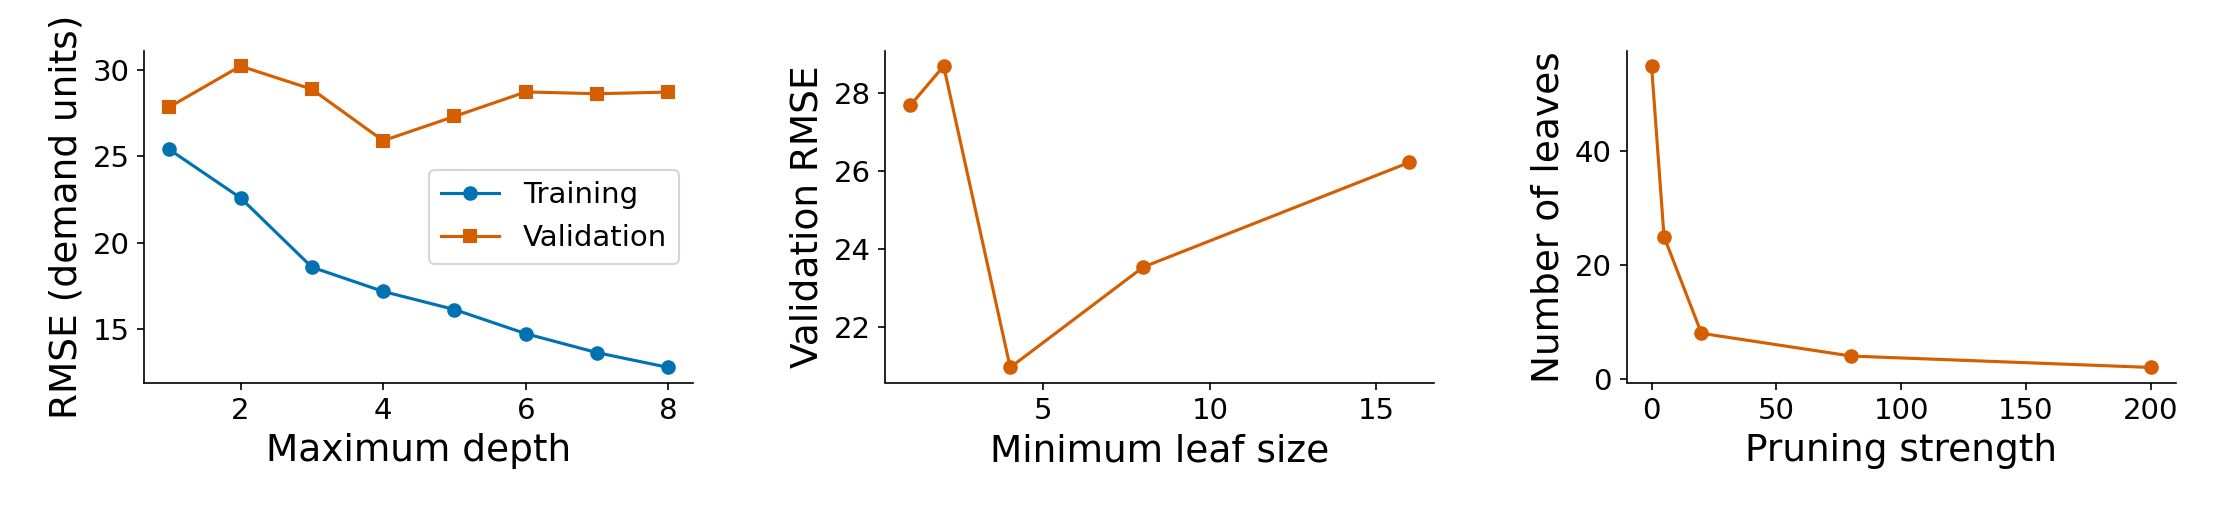

In [66]:
# Lecture code 4.9.10
(fig, aa) = canvas(3)
aa[0].plot(depths, depth_train, 'o-', color=COL['Linear'], label='Training')
aa[0].plot(depths, depth_val, 's-', color=COL['Tree'], label='Validation')
aa[0].set(xlabel='Maximum depth', ylabel='RMSE (demand units)')
aa[0].legend(loc='best', fontsize=14)
aa[1].plot(leaves, [rmse(val.demand, m.predict(val[features])) for m in leaf_models], 'o-', color=COL['Tree'])
aa[1].set(xlabel='Minimum leaf size', ylabel='Validation RMSE')
aa[2].plot(prunes, [m.get_n_leaves() for m in pruned], 'o-', color=COL['Tree'])
aa[2].set(xlabel='Pruning strength', ylabel='Number of leaves')
save(fig, 'ex11_complexity_validation', 'Measure depth and leaf-size errors; show pruning reducing leaves', 'Classroom synthetic demand snapshot, chronological training and validation', [14])

<a id="example-4-10"></a>
## 4.10 — Select depth and leaf size together

A grid tries a list of candidate settings; here every depth/leaf-size pair is compared.



**Work through the example**
1. Cross eight maximum depths with five minimum leaf sizes, producing forty candidate pairs.
2. Fit each candidate using the same 124 training rows and evaluate it on the same 27 validation rows.
3. Select the pair with the smallest validation RMSE. This run chooses depth five and leaf size four, with validation RMSE about 20.63.
4. Read the marked heatmap cell, then carry that pair to refitting. The final test is not used to select it.

### 4.10.1 — Read before running

Fit all permitted depth/leaf-size pairs using training outcomes only. Model candidates see identical training rows.

In [67]:
# Lecture code 4.10.1
tree_grid = {(d, l): DecisionTreeRegressor(max_depth=d, min_samples_leaf=l, random_state=417).fit(X, y) for d in depths for l in leaves}

### 4.10.2 — Read before running

Fit all permitted depth/leaf-size pairs using training outcomes only. Model candidates see identical training rows.

In [68]:
# Lecture code 4.10.2
grid_scores = {k: rmse(val.demand, m.predict(val[features])) for (k, m) in tree_grid.items()}

### 4.10.3 — Read before running

Predict the fixed validation rows for each candidate and calculate the same RMSE. The test is not used for this choice.

In [69]:
# Lecture code 4.10.3
(best_depth, best_leaf) = min(grid_scores, key=grid_scores.get)

### 4.10.4 — Read before running

Predict the fixed validation rows for each candidate and calculate the same RMSE. The test is not used for this choice.

In [70]:
# Lecture code 4.10.4
pd.DataFrame([dict(depth=d, min_leaf=l, validation_RMSE=v) for ((d, l), v) in grid_scores.items()]).to_csv(OUT / 'tree_joint_grid.csv', index=False)

### 4.10.5 — Read before running

Plot the values or fitted rule computed above. Read the marked heatmap cell, then carry that pair to refitting. The final test is not used to select it. The saved image is the same figure referenced by Example 4.10 in the notes and slides.

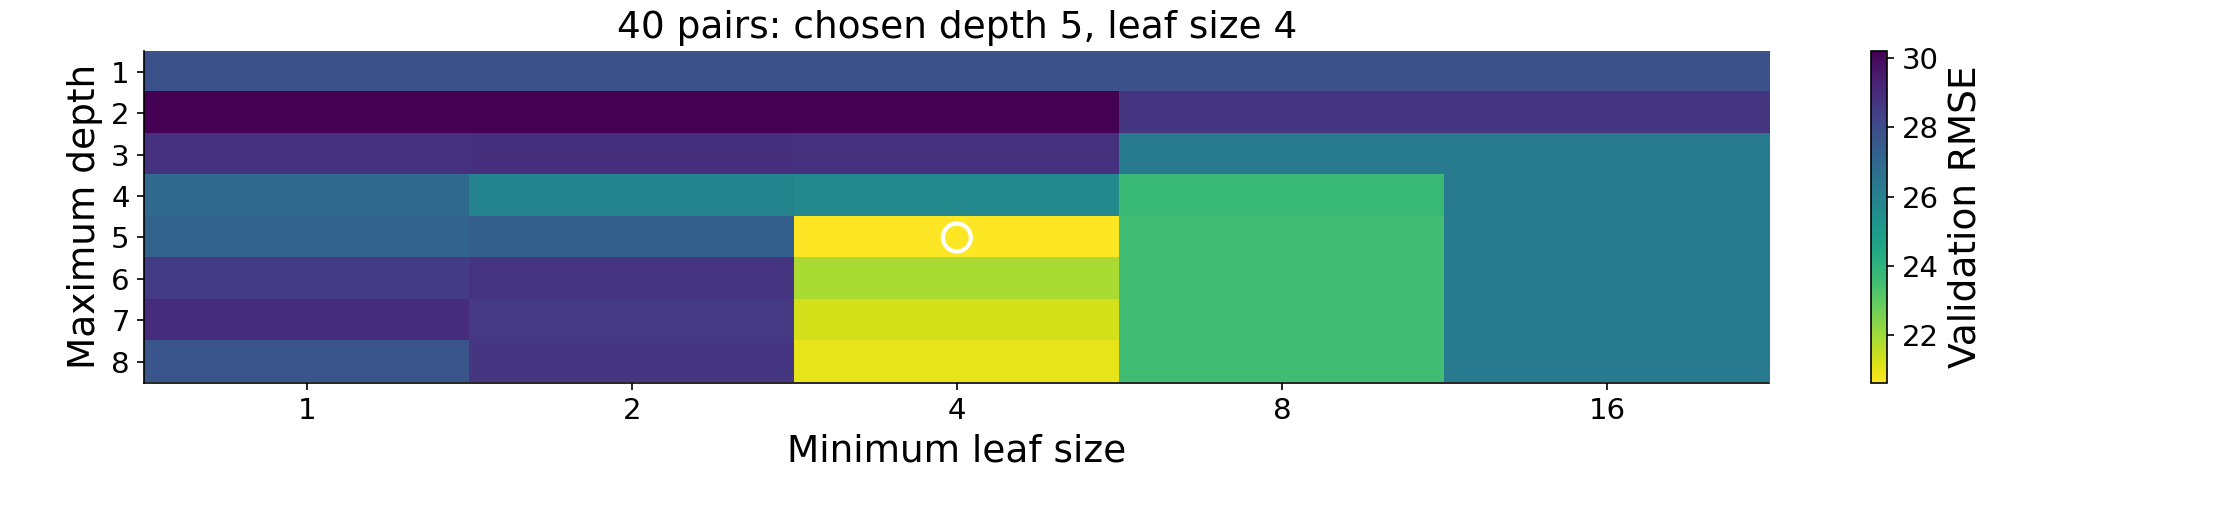

In [71]:
# Lecture code 4.10.5
(fig, aa) = canvas()
mat = np.array([[grid_scores[d, l] for l in leaves] for d in depths])
im = aa[0].imshow(mat, aspect='auto', cmap='viridis_r')
aa[0].set(xticks=range(len(leaves)), xticklabels=leaves, yticks=range(len(depths)), yticklabels=depths, xlabel='Minimum leaf size', ylabel='Maximum depth')
fig.colorbar(im, ax=aa[0], label='Validation RMSE')
aa[0].scatter([leaves.index(best_leaf)], [depths.index(best_depth)], s=180, facecolors='none', edgecolors='white', linewidths=2)
aa[0].set_title(f'40 pairs: chosen depth {best_depth}, leaf size {best_leaf}', fontsize=18)
save(fig, 'ex29_joint_grid', 'Choose a depth/leaf-size pair using the same validation dates', 'Classroom simulation; 8 depths × 5 leaf sizes', [])

### 4.10.6 — Read before running

Put the calculated values in a labeled table. The table is an output of the current run, not a manually typed performance claim.

In [72]:
# Lecture code 4.10.6
pd.DataFrame({'depth': depths, 'train_RMSE': depth_train, 'validation_RMSE': depth_val}).to_csv(OUT / 'tree_depth.csv', index=False)

<a id="example-4-11"></a>
## 4.11 — Change one leaf while fixing the query

A model-sensitivity comparison keeps the prediction case fixed.



**Work through the example**
1. Keep the right-leaf outcomes 60,64,68,72 and the traffic threshold 50. Their mean is 66.
2. Replace only the first outcome, 60, with 100. The right-leaf mean becomes 76.
3. Query the same input 75 before and after the replacement. The prediction rises by ten without changing the case.
4. This holds the split fixed to isolate the leaf average. It is not a claim that a newly optimized full tree must retain the same split.

### 4.11.1 — Read before running

Plot the values or fitted rule computed above. This holds the split fixed to isolate the leaf average. It is not a claim that a newly optimized full tree must retain the same split. The saved image is the same figure referenced by Example 4.11 in the notes and slides.

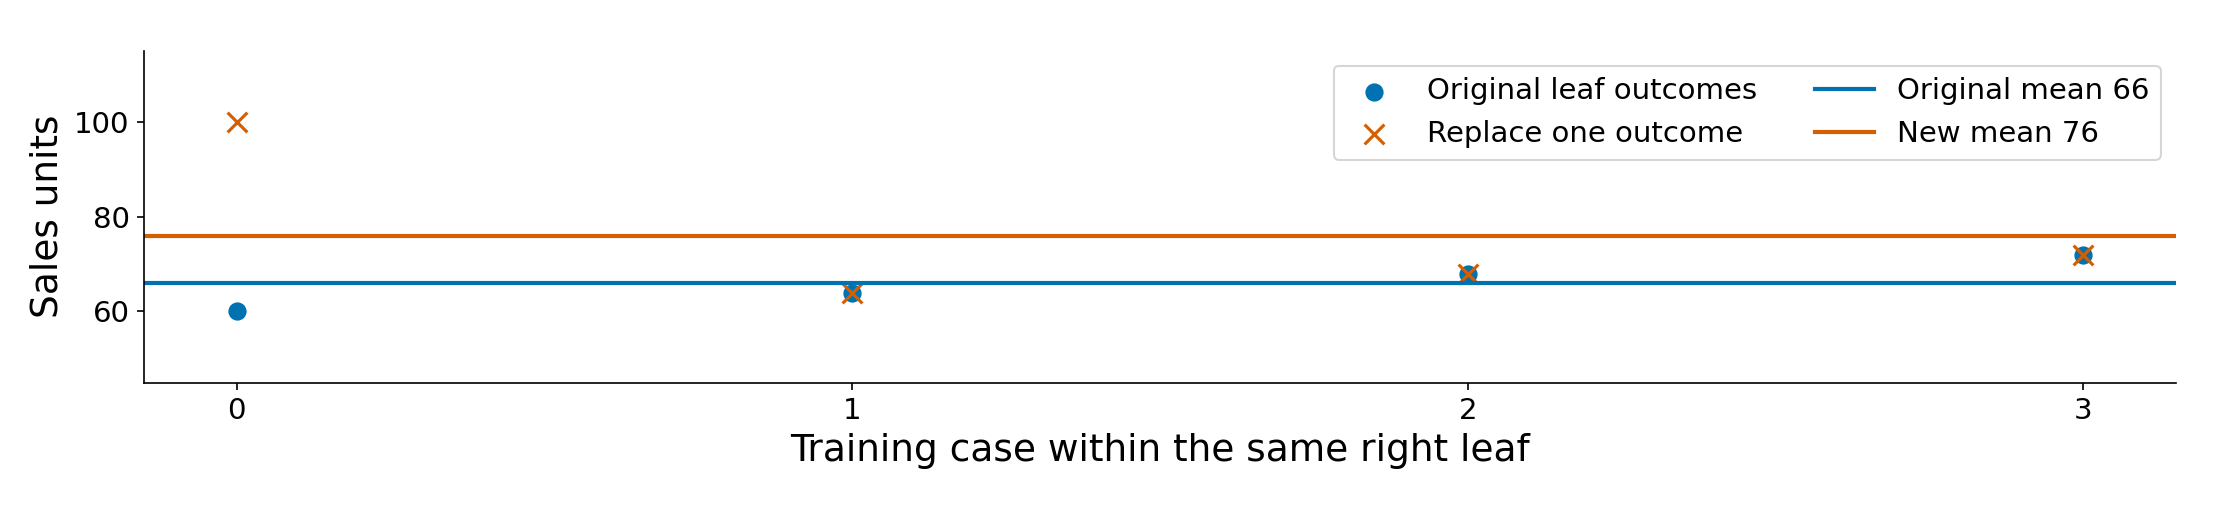

In [73]:
# Lecture code 4.11.1
(fig, aa) = canvas()
before = np.array([60, 64, 68, 72])
after = np.array([100, 64, 68, 72])
aa[0].scatter(range(4), before, color=COL['Linear'], s=60, label='Original leaf outcomes')
aa[0].scatter(range(4), after, color=COL['Tree'], marker='x', s=90, label='Replace one outcome')
aa[0].axhline(before.mean(), color=COL['Linear'], lw=2, label='Original mean 66')
aa[0].axhline(after.mean(), color=COL['Tree'], lw=2, label='New mean 76')
aa[0].set(xlabel='Training case within the same right leaf', ylabel='Sales units', xticks=range(4), ylim=(45, 115))
aa[0].legend(loc='upper right', ncol=2, fontsize=14)
save(fig, 'ex12_fixed_case_sensitivity', 'A changed leaf average shifts prediction for the same traffic 75', 'Four constructed right-leaf outcomes; same split held fixed', [15])

<a id="example-4-12"></a>
## 4.12 — Expand one model into a forest

An ensemble combines fitted models; a random forest averages varied fitted trees.

A base learner is one fitted model in an ensemble. A forest is a collection of trees; random refers to deliberate variation in constructing them.

**Work through the example**
1. Identify one decision-tree diagram as one base learner, using the node and leaf meanings established in Example 4.4.
2. Expand it into a collection of seven schematic trees. Different structures represent possible fitted rules; seven is a drawing choice, not a required forest size.
3. Send the same known input case through all member rules rather than comparing different cases.
4. Combine the numerical predictions by their mean. The next examples show how rows and candidate inputs vary and how the average is computed.

### 4.12.1 — Read before running

Calculate or set `course` for this example. Identify one decision-tree diagram as one base learner, using the node and leaf meanings established in Example 4.4. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [74]:
# Lecture code 4.12.1
course = LECTURE.parent

### 4.12.2 — Read before running

Calculate or set `source` for this example. Expand it into a collection of seven schematic trees. Different structures represent possible fitted rules; seven is a drawing choice, not a required forest size. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [75]:
source = NOTEBOOK_ROOT / 'resources/tree_forest.py'

### 4.12.3 — Read before running

Save and display the computed graph used by the notes and slides. Read its axes, sample, units and held-fixed conditions before drawing a conclusion.

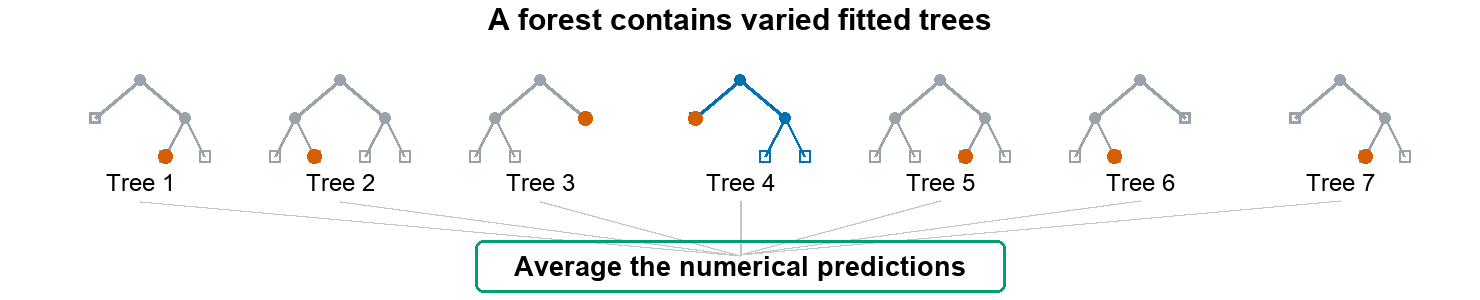

In [76]:
spec=importlib.util.spec_from_file_location('tree_forest',source)
tf=importlib.util.module_from_spec(spec);spec.loader.exec_module(tf)
a={'slide': 16, 'source_topic_slide': 16, 'stages': [{'id': 'single', 'at': 0.0}, {'id': 'base', 'at': 3.555555555555556}, {'id': 'forest', 'at': 12.0}, {'id': 'random', 'at': 14.666666666666666}, {'id': 'case', 'at': 23.555555555555557}, {'id': 'average', 'at': 29.77777777777778}]}
im=tf.render(a,max(s['at'] for s in a['stages'])+3)
name='ex27_forest_s16'
im.save(GRAPH/f'{name}.png')
from IPython.display import display
display(im)
records.append(dict(id=name,description='Code-rendered tree/forest diagram',data_source='Constructed illustration',slides=[16],code='Lecture_04_Coding_Note.ipynb',figure=f'figures/{name}.png'))

<a id="example-4-13"></a>
## 4.13 — Draw training rows with replacement

With replacement means a selected row remains eligible to be drawn again.



**Work through the example**
1. Start both draws from the same training pool A,B,C,D. The second tree does not draw from the first tree's bag.
2. The first constructed draw is A,A,C,D: A repeats and B is absent.
3. The second draw is A,B,B,D: B repeats and C is absent. Each bag still contains four selected rows.
4. The branching arrows show parallel resampling from the original pool. Every row must belong to the permitted training history.

### 4.13.1 — Read before running

Plot the values or fitted rule computed above. The branching arrows show parallel resampling from the original pool. Every row must belong to the permitted training history. The saved image is the same figure referenced by Example 4.13 in the notes and slides.

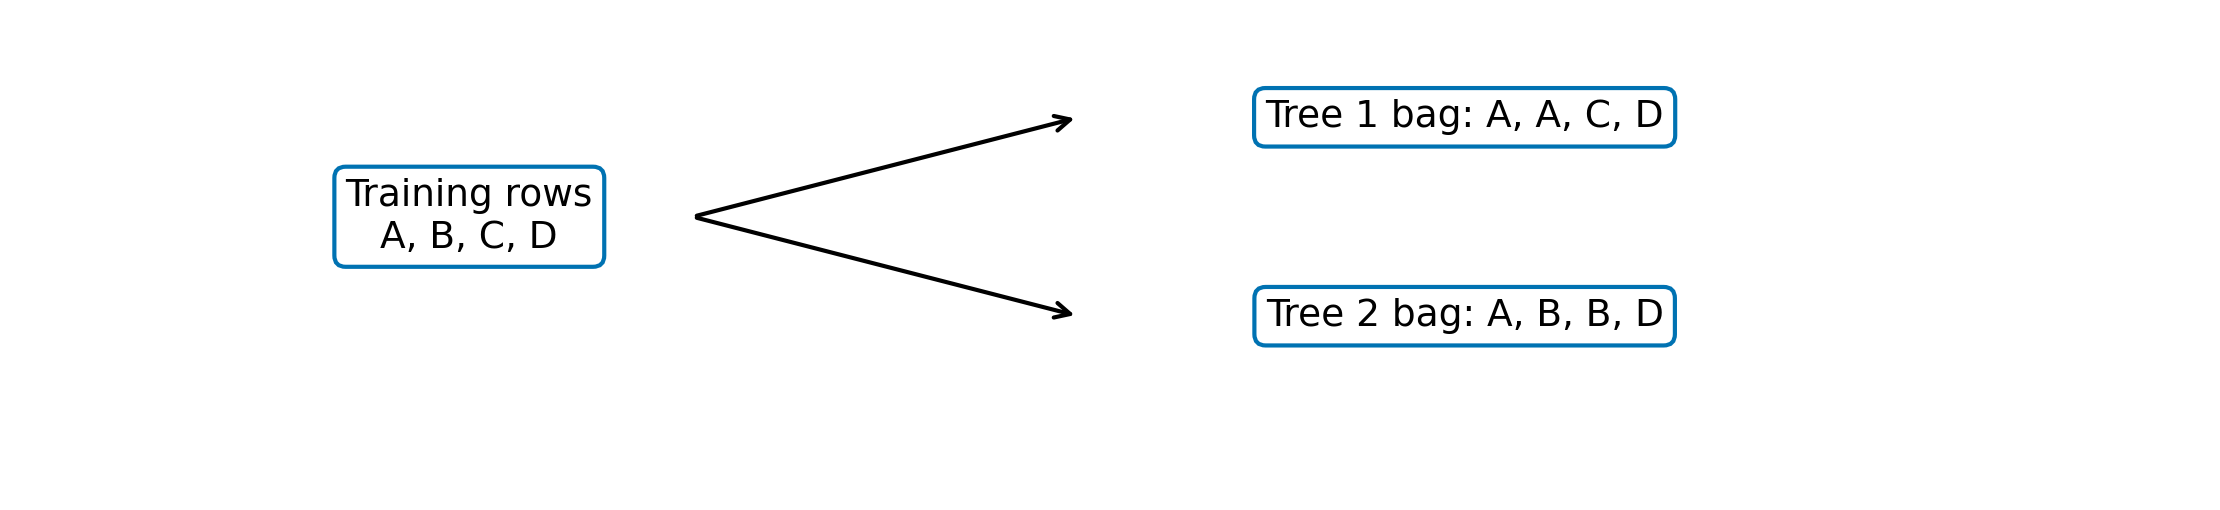

In [77]:
# Lecture code 4.13.1
(fig, aa) = canvas()
ax = aa[0]
ax.axis('off')
for (xx, yy, label) in [(0.16, 0.5, 'Training rows\nA, B, C, D'), (0.65, 0.8, 'Tree 1 bag: A, A, C, D'), (0.65, 0.2, 'Tree 2 bag: A, B, B, D')]:
    ax.text(xx, yy, label, ha='center', va='center', fontsize=18, bbox=dict(boxstyle='round', facecolor='white', edgecolor=COL['Linear'], lw=2))
for yy in [0.8, 0.2]:
    ax.annotate('', xy=(0.46, yy), xytext=(0.27, 0.5), arrowprops=dict(arrowstyle='->', lw=2))
save(fig, 'ex13_bootstrap', 'Both with-replacement bags are drawn from the original training pool', 'Constructed row identifiers; parallel resampling', [17])

<a id="example-4-14"></a>
## 4.14 — Inspect candidate feature draws

Feature subsampling restricts the input columns that may compete at a split.

A random seed initializes a reproducible sequence of random choices. It does not replace a change in training data.

**Work through the example**
1. Use four illustrative input names: Traffic, Advertising, Weather and Promotion.
2. With seed 417, draw two distinct candidate columns at each of three illustrative nodes. The generated pairs are Promotion/Traffic, Advertising/Promotion and Promotion/Advertising.
3. The third pair repeats the second set in a different order. Random draws may repeat a subset; different draws need not produce different sets.
4. A fixed seed reproduces these choices. It does not test sensitivity to a different training sample.

### 4.14.1 — Read before running

Calculate or set `rng` for this example. Use four illustrative input names: Traffic, Advertising, Weather and Promotion. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [78]:
# Lecture code 4.14.1
rng = np.random.default_rng(417)

### 4.14.2 — Read before running

Calculate or set `columns` for this example. With seed 417, draw two distinct candidate columns at each of three illustrative nodes. The generated pairs are Promotion/Traffic, Advertising/Promotion and Promotion/Advertising. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [79]:
# Lecture code 4.14.2
columns = np.array(['Traffic', 'Advertising', 'Weather', 'Promotion'])

### 4.14.3 — Read before running

Calculate or set `draws` for this example. The third pair repeats the second set in a different order. Random draws may repeat a subset; different draws need not produce different sets. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [80]:
# Lecture code 4.14.3
draws = [rng.choice(columns, 2, replace=False) for _ in range(3)]

### 4.14.4 — Read before running

Draw the stated mechanism with labels. This is an explicitly constructed conceptual diagram, not evidence that one model forecasts better.

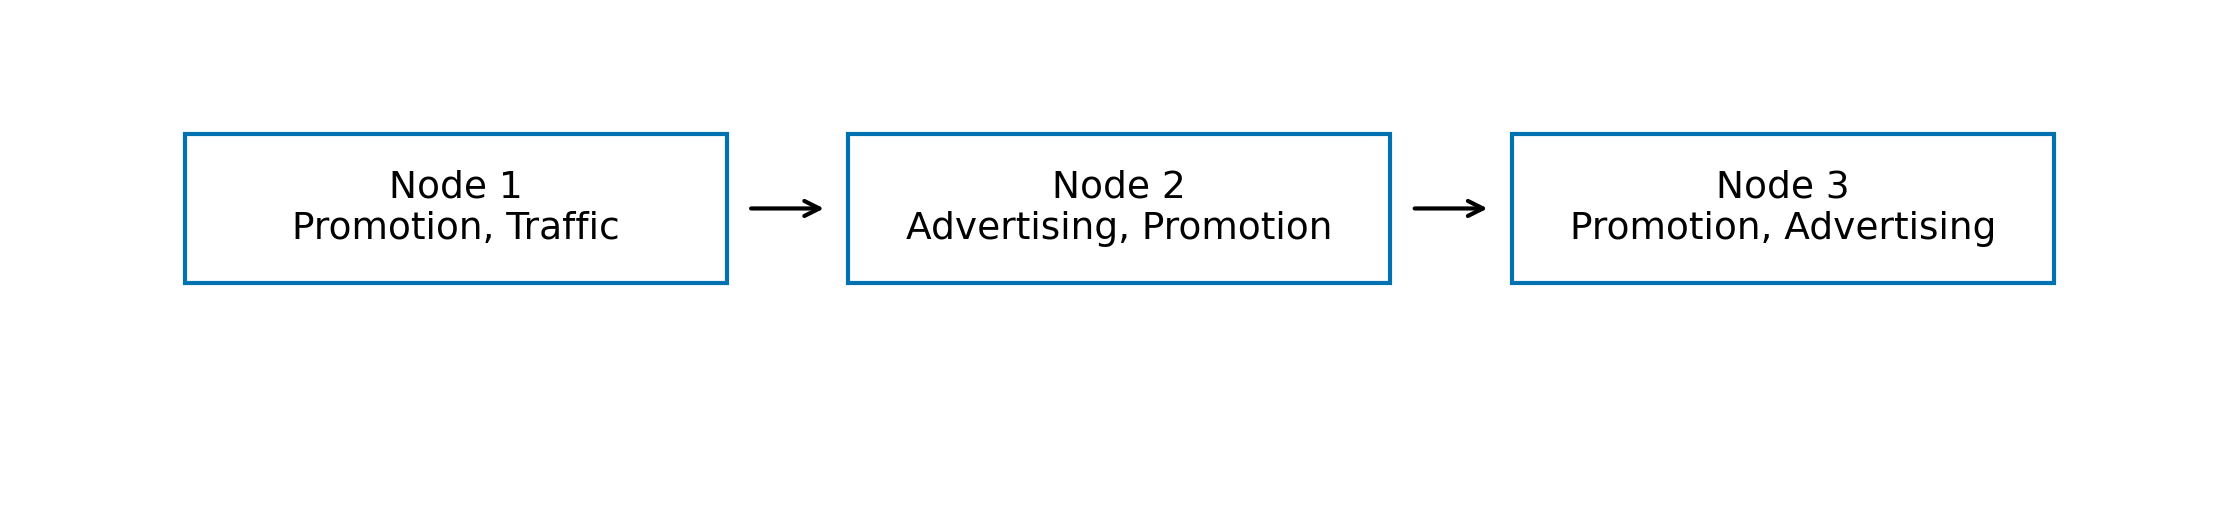

In [81]:
# Lecture code 4.14.4
flow('ex14_feature_draws', [f'Node {i + 1}\n' + ', '.join(v) for (i, v) in enumerate(draws)], 'Explicit candidate-column draws at three nodes', [18])

<a id="example-4-15"></a>
## 4.15 — Fit three trees and average one shared query

A regression forest averages numerical member predictions for the same case.



**Work through the example**
1. Use a six-row constructed pool: identifiers L,A,B,C,D,E; inputs [-1,1,1,1,1,1]; outcomes [10,40,50,60,70,80].
2. Fit three depth-one trees to bags [L,A,A,B,C,C], [L,A,B,C,D,E] and [L,C,C,D,E,E]. Each learned root splits x at zero.
3. Query x=1. The right-leaf outcome means are 50,60,70. These are predictions of the actual fitted trees, not numbers attached to unrelated tree pictures.
4. Add 50+60+70 and divide by three to get 60. The left query x=-1 would return 10 from every tree.

### 4.15.1 — Read before running

Calculate or set `pool_x` for this example. Use a six-row constructed pool: identifiers L,A,B,C,D,E; inputs [-1,1,1,1,1,1]; outcomes [10,40,50,60,70,80]. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [82]:
# Lecture code 4.15.1
pool_x = np.array([-1, 1, 1, 1, 1, 1])

### 4.15.2 — Read before running

Calculate or set `pool_y` for this example. Fit three depth-one trees to bags [L,A,A,B,C,C], [L,A,B,C,D,E] and [L,C,C,D,E,E]. Each learned root splits x at zero. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [83]:
# Lecture code 4.15.2
pool_y = np.array([10, 40, 50, 60, 70, 80])

### 4.15.3 — Read before running

Calculate or set `pool_ids` for this example. Query x=1. The right-leaf outcome means are 50,60,70. These are predictions of the actual fitted trees, not numbers attached to unrelated tree pictures. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [84]:
# Lecture code 4.15.3
pool_ids = np.array(['L', 'A', 'B', 'C', 'D', 'E'])

### 4.15.4 — Read before running

Calculate or set `bags` for this example. Query x=1. The right-leaf outcome means are 50,60,70. These are predictions of the actual fitted trees, not numbers attached to unrelated tree pictures. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [85]:
# Lecture code 4.15.4
bags = [[0, 1, 1, 2, 3, 3], [0, 1, 2, 3, 4, 5], [0, 3, 3, 4, 5, 5]]

### 4.15.5 — Read before running

Calculate or set `member_preds` for this example. Query x=1. The right-leaf outcome means are 50,60,70. These are predictions of the actual fitted trees, not numbers attached to unrelated tree pictures. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [86]:
# Lecture code 4.15.5
member_preds = []

### 4.15.6 — Read before running

Retain the three fitted trees so that their actual branches and leaf values can be inspected.

In [87]:
# Lecture code 4.15.6
member_trees = []

### 4.15.7 — Read before running

Retain the three fitted trees so that their actual branches and leaf values can be inspected.

In [88]:
# Lecture code 4.15.7
for bag in bags:
    m = DecisionTreeRegressor(max_depth=1, random_state=417).fit(pool_x[bag, None], pool_y[bag])
    member_trees.append(m)
    member_preds.append(float(m.predict([[1]])[0]))

### 4.15.8 — Read before running

Retain the three fitted trees so that their actual branches and leaf values can be inspected.

In [89]:
# Lecture code 4.15.8
assert np.allclose(member_preds, [50, 60, 70]) and all((m.tree_.threshold[0] == 0 for m in member_trees))

### 4.15.9 — Read before running

Retain the calculated values of this example so they can be compared with the worked steps and exported tables.

In [90]:
# Lecture code 4.15.9
worked_values['forest_average'] = {'pool_ids': pool_ids.tolist(), 'x': pool_x.tolist(), 'y': pool_y.tolist(), 'bags': [pool_ids[b].tolist() for b in bags], 'case_x': 1, 'tree_predictions': member_preds, 'forest_average': float(np.mean(member_preds))}
display(worked_values['forest_average'])

{'pool_ids': ['L', 'A', 'B', 'C', 'D', 'E'],
 'x': [-1, 1, 1, 1, 1, 1],
 'y': [10, 40, 50, 60, 70, 80],
 'bags': [['L', 'A', 'A', 'B', 'C', 'C'],
  ['L', 'A', 'B', 'C', 'D', 'E'],
  ['L', 'C', 'C', 'D', 'E', 'E']],
 'case_x': 1,
 'tree_predictions': [50.0, 60.0, 70.0],
 'forest_average': 60.0}

### 4.15.10 — Read before running

Plot the values or fitted rule computed above. Add 50+60+70 and divide by three to get 60. The left query x=-1 would return 10 from every tree. The saved image is the same figure referenced by Example 4.15 in the notes and slides.

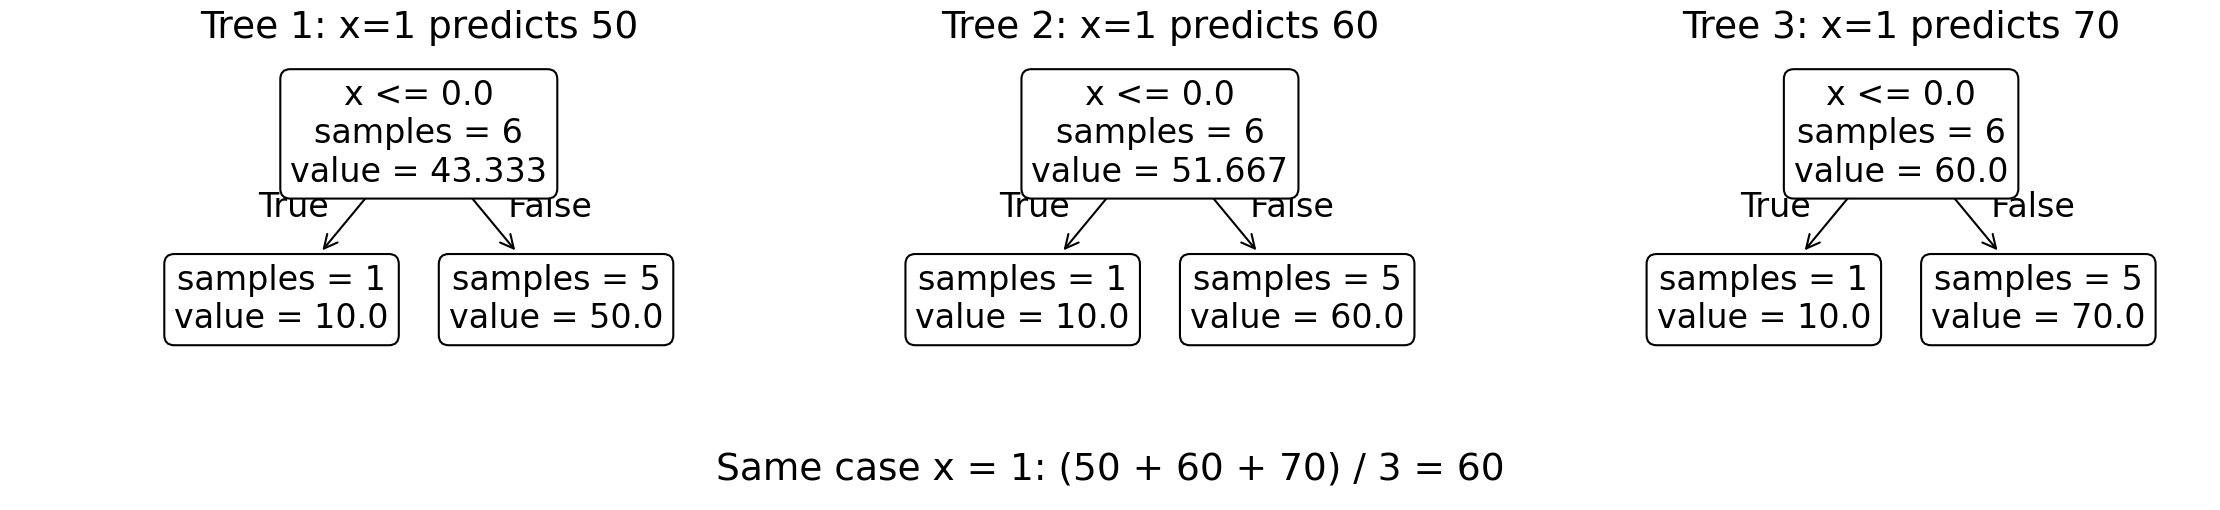

In [91]:
# Lecture code 4.15.10
(fig, aa) = canvas(3)
for (j, (ax, m)) in enumerate(zip(aa, member_trees)):
    plot_tree(m, ax=ax, feature_names=['x'], impurity=False, rounded=True, fontsize=16)
    ax.set_title(f'Tree {j + 1}: x=1 predicts {member_preds[j]:.0f}', fontsize=18)
fig.text(0.5, 0.06, 'Same case x = 1: (50 + 60 + 70) / 3 = 60', ha='center', fontsize=18)
save(fig, 'ex15_forest_average', 'Three actual branched trees fitted to stated with-replacement bags; same case x=1', 'Six-row constructed pool; fitted stumps, not arbitrary tree pictures', [19])

<a id="example-4-16"></a>
## 4.16 — Compare offsetting and shared errors

Averaging can offset differing errors but cannot remove an identical shared error.



**Work through the example**
1. Hold the target case fixed. Construct three errors +6,-3,-3, expressed as prediction minus target.
2. Calculate their mean: zero. The plotted average marker falls on the zero-error reference.
3. Now change the error vector to +6,+6,+6. Its mean remains +6; the average marker stays on the same side as every member.
4. These are controlled illustrations of cancellation and shared error, not a proof that a forest achieves a given accuracy.

### 4.16.1 — Read before running

Plot the values or fitted rule computed above. These are controlled illustrations of cancellation and shared error, not a proof that a forest achieves a given accuracy. The saved image is the same figure referenced by Example 4.16 in the notes and slides.

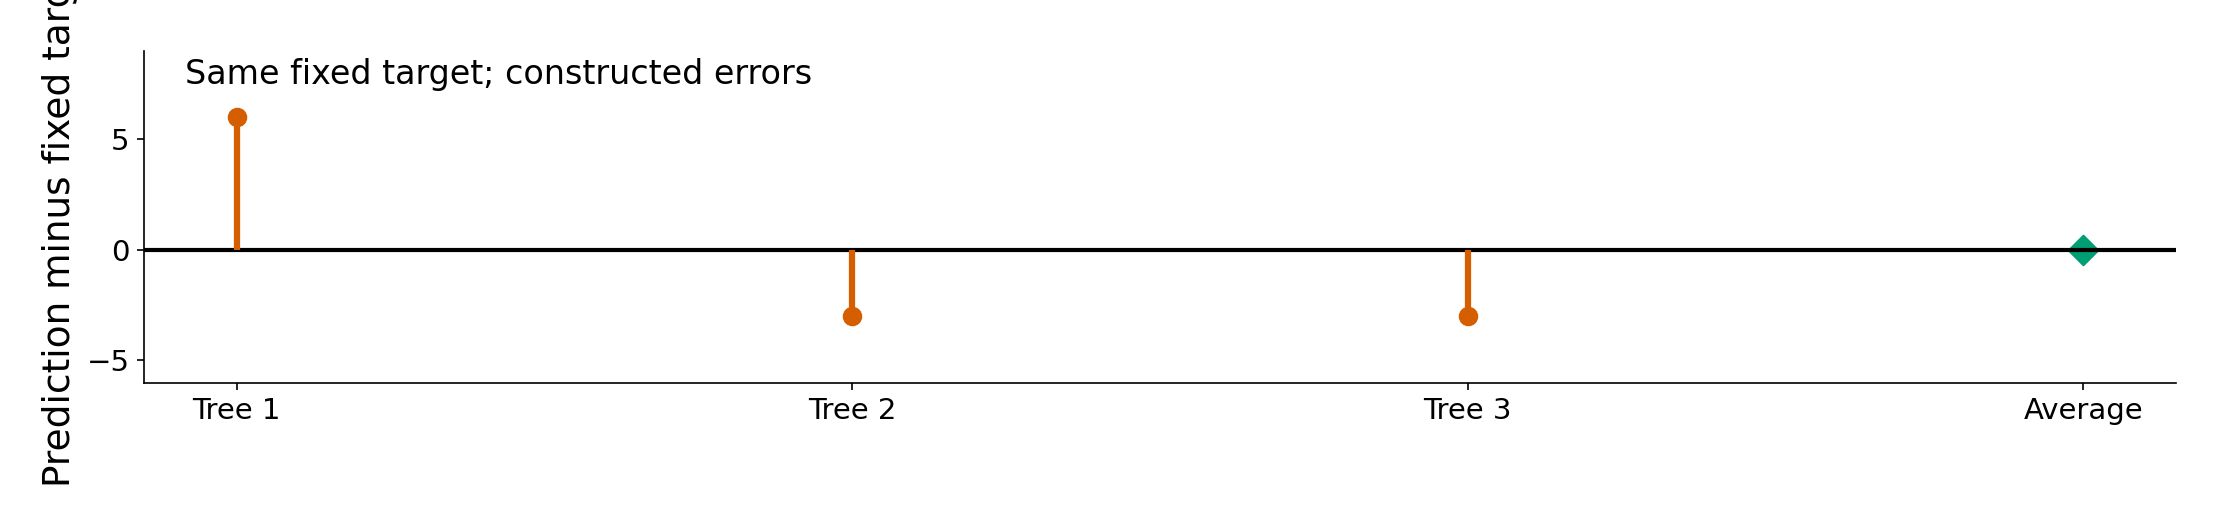

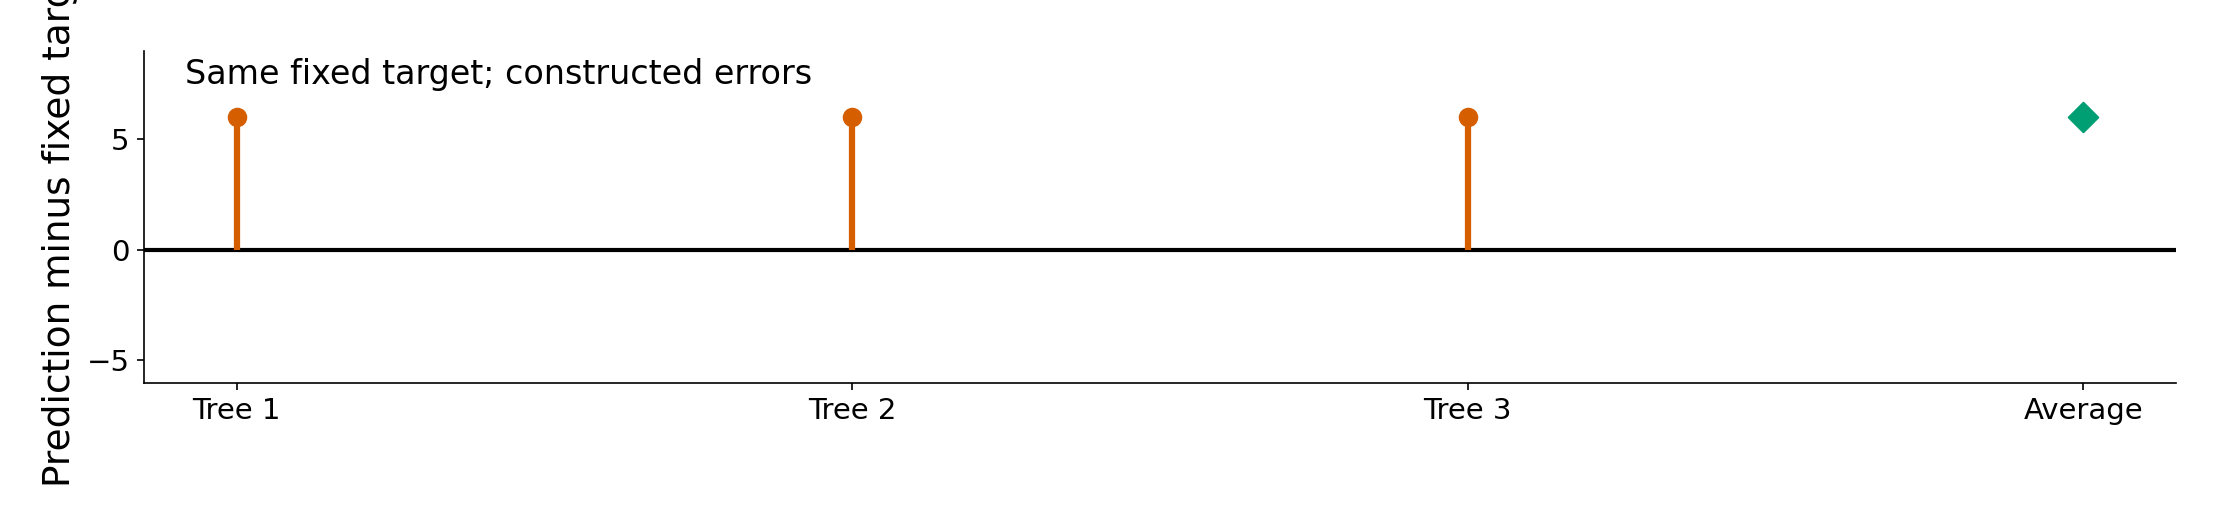

In [92]:
# Lecture code 4.16.1
for (name, errors, slides) in [('ex16_offset_errors', [6, -3, -3], [20]), ('ex17_shared_errors', [6, 6, 6], [21])]:
    (fig, aa) = canvas()
    ax = aa[0]
    ax.axhline(0, color='black', lw=2)
    ax.vlines(range(3), 0, errors, color=COL['Tree'], lw=3)
    ax.scatter(range(3), errors, color=COL['Tree'], s=70)
    ax.scatter([3], [np.mean(errors)], color=COL['Forest'], marker='D', s=100)
    ax.set(xticks=range(4), xticklabels=['Tree 1', 'Tree 2', 'Tree 3', 'Average'], ylabel='Prediction minus fixed target', ylim=(-6, 9))
    note(ax, 'Same fixed target; constructed errors')
    save(fig, name, 'Compare individual errors and their arithmetic mean', 'Constructed errors for one common case', slides)

<a id="example-4-17"></a>
## 4.17 — Keep the forest inside chronological training

Random tree construction does not authorize future rows in the training history.



**Work through the example**
1. Reuse the chronological blocks from Example 4.8: 124 training, 27 validation and 27 test rows.
2. Permit internal bootstrap draws only from the current training block. Feature-subset settings concern columns, not permission to move future dates into training.
3. Use validation to choose development settings and retain the final test for the settled procedure.
4. Distinguish the learner's row resampling from the block-bootstrap uncertainty calculation introduced in Lecture 2.

### 4.17.1 — Read before running

Draw the stated mechanism with labels. This is an explicitly constructed conceptual diagram, not evidence that one model forecasts better.

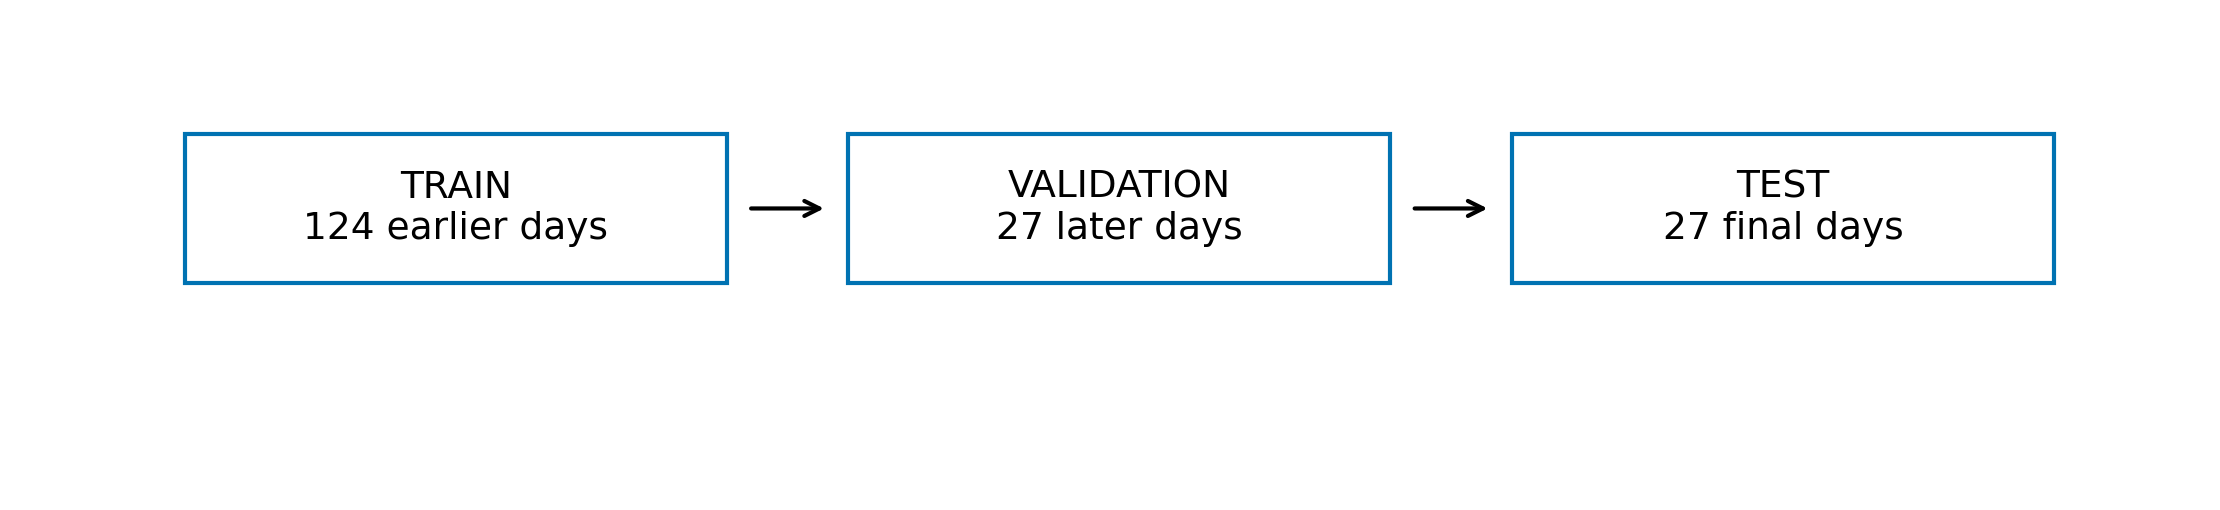

In [93]:
# Lecture code 4.17.1
flow('ex18_time_blocks', [f'TRAIN\n{len(train)} earlier days', f'VALIDATION\n{len(val)} later days', f'TEST\n{len(test)} final days'], 'Chronological split; all input lags observed before the target', [22])

### 4.17.2 — Read before running

Calculate or set `linear` for this example. Permit internal bootstrap draws only from the current training block. Feature-subset settings concern columns, not permission to move future dates into training. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [94]:
# Lecture code 4.17.2
linear = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)

### 4.17.3 — Read before running

Calculate or set `quad` for this example. Use validation to choose development settings and retain the final test for the settled procedure. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [95]:
# Lecture code 4.17.3
quad = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), LinearRegression()).fit(X, y)

### 4.17.4 — Read before running

Fit the ridge candidates on training rows and compare their later validation errors; a numerical strength has the package-defined scaling.

In [96]:
# Lecture code 4.17.4
ridge_grid = {alpha: make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(X, y) for alpha in [0.1, 1, 10, 100]}

### 4.17.5 — Read before running

Fit the ridge candidates on training rows and compare their later validation errors; a numerical strength has the package-defined scaling.

In [97]:
# Lecture code 4.17.5
best_alpha = min(ridge_grid, key=lambda k: rmse(val.demand, ridge_grid[k].predict(val[features])))

### 4.17.6 — Read before running

Fit the classroom forest with the stated preset controls. Bootstrap rows and the one-candidate feature setting provide deliberate fitting variation.

In [98]:
# Lecture code 4.17.6
forest = RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=8, max_features=1, random_state=417, n_jobs=1).fit(X, y)

### 4.17.7 — Read before running

Fit all permitted depth/leaf-size pairs using training outcomes only. Model candidates see identical training rows.

In [99]:
# Lecture code 4.17.7
models = {'Linear': linear, 'Quadratic': quad, 'Ridge': ridge_grid[best_alpha], 'Tree': tree_grid[best_depth, best_leaf], 'Forest': forest}

<a id="example-4-18"></a>
## 4.18 — Normalize three split-credit totals

Normalizing divides each credit by a positive total so the shares sum to one.



**Work through the example**
1. Use the constructed raw credits 60,30,10 for three illustrative inputs. This hand calculation is separate from the two-input classroom forest.
2. Add the credits: the total is 100.
3. Divide each credit by 100 to obtain 0.60,0.30,0.10, and check that the shares sum to one.
4. Read these as shares of the chosen training split score, not percentages of future accuracy.

### 4.18.1 — Read before running

Set three constructed training-credit totals. This hand normalization is distinct from the later fitted two-input forest.

In [100]:
# Lecture code 4.18.1
credits = np.array([60.0, 30.0, 10.0])

### 4.18.2 — Read before running

Divide each credit by the positive total. Check both the individual fractions and their sum.

In [101]:
# Lecture code 4.18.2
shares = credits / credits.sum()

### 4.18.3 — Read before running

Retain the calculated values of this example so they can be compared with the worked steps and exported tables.

In [102]:
# Lecture code 4.18.3
worked_values['normalization'] = {'credits': credits.tolist(), 'total': float(credits.sum()), 'shares': shares.tolist()}
display(worked_values['normalization'])

{'credits': [60.0, 30.0, 10.0], 'total': 100.0, 'shares': [0.6, 0.3, 0.1]}

### 4.18.4 — Read before running

Plot the values or fitted rule computed above. Read these as shares of the chosen training split score, not percentages of future accuracy. The saved image is the same figure referenced by Example 4.18 in the notes and slides.

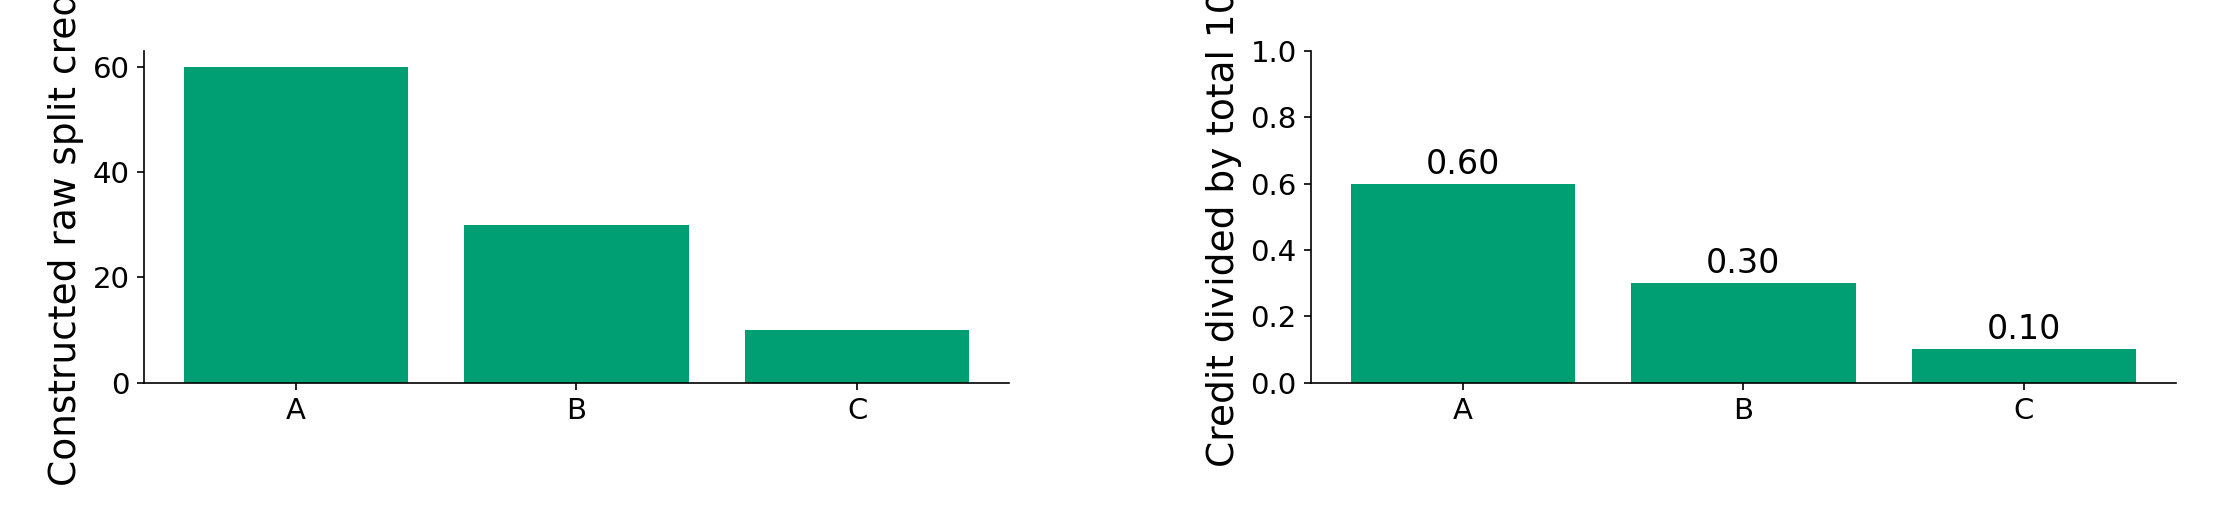

In [103]:
# Lecture code 4.18.4
(fig, aa) = canvas(2)
aa[0].bar(['A', 'B', 'C'], credits, color=COL['Forest'])
aa[0].set(ylabel='Constructed raw split credits')
aa[1].bar(['A', 'B', 'C'], shares, color=COL['Forest'])
aa[1].set(ylabel='Credit divided by total 100', ylim=(0, 1))
for (j, v) in enumerate(shares):
    aa[1].text(j, v + 0.03, f'{v:.2f}', ha='center', fontsize=16)
save(fig, 'ex31_normalization', 'Calculate 60/100, 30/100 and 10/100 before reading the measured forest score', 'Three constructed credits; separate from the two-input classroom forest', [])

<a id="example-4-19"></a>
## 4.19 — Read the fitted forest importance

Feature importance measures a fitted model's use of an input under a specified scoring procedure.

Minimum split size is the number of observations a node must contain before a split may be attempted. It differs from minimum leaf size, which constrains the final groups.

**Work through the example**
1. Fit the classroom forest on the 124 training rows with 100 trees, depth five, minimum leaf size eight, one candidate input per split and seed 417.
2. Read the fitted training split-credit shares for the two lagged-demand inputs. They are approximately 0.699 and 0.301.
3. Check the total of the positive normalized shares. The two-input score is not the separate three-input normalization example.
4. Keep training split importance distinct from permutation importance: one credits training splits; the other changes input alignment and reevaluates a fixed model.
5. As a separate edge case, fit a forest with minimum split size 200 to only 124 training rows. It cannot form effective splits, and both importance entries are zero. This is not a set of normalized positive credits.

### 4.19.1 — Read before running

Plot the values or fitted rule computed above. As a separate edge case, fit a forest with minimum split size 200 to only 124 training rows. It cannot form effective splits, and both importance entries are zero. This is not a set of normalized positive credits. The saved image is the same figure referenced by Example 4.19 in the notes and slides.

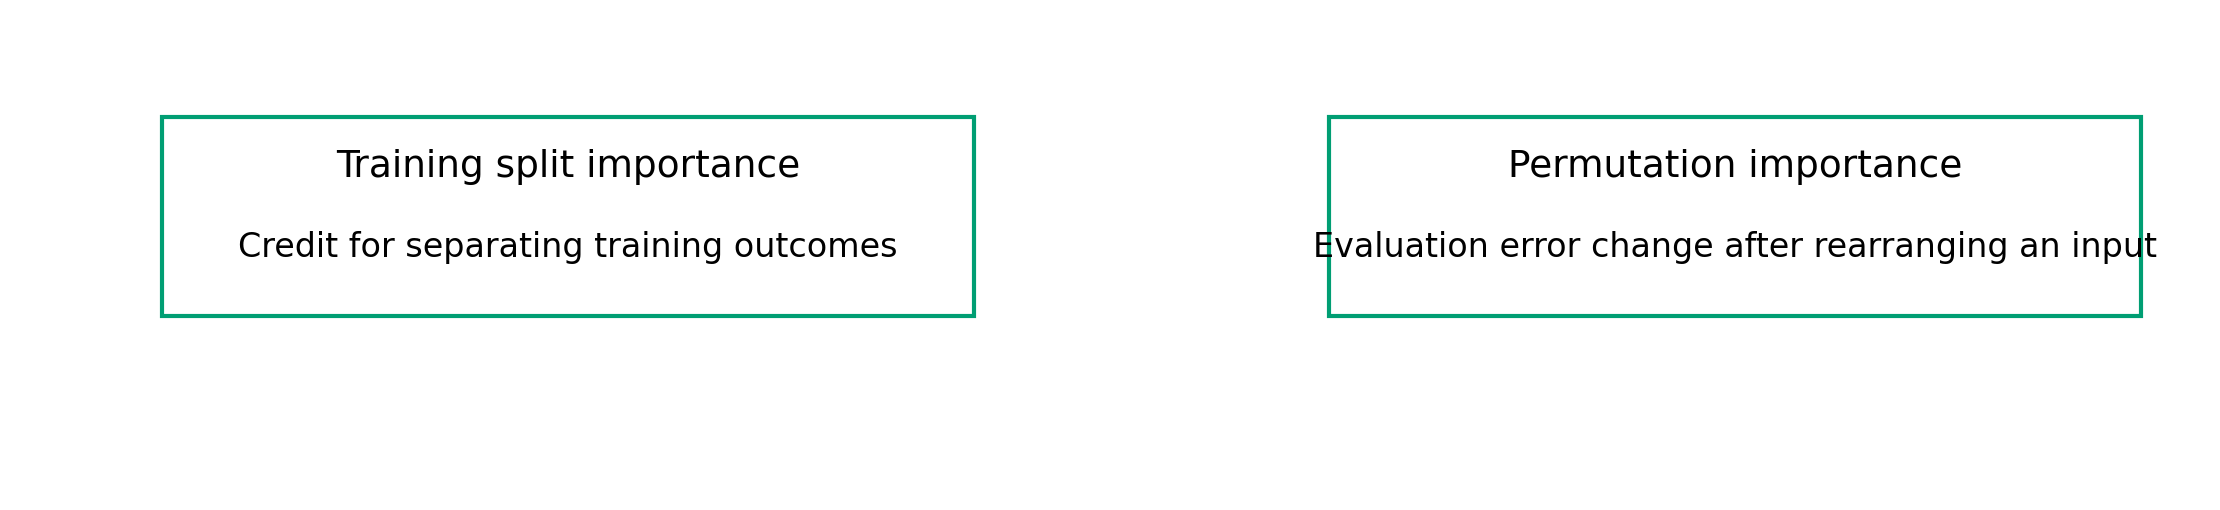

In [104]:
# Lecture code 4.19.1
(fig, aa) = canvas(2)
for (ax, head, body) in zip(aa, ['Training split importance', 'Permutation importance'], ['Credit for separating training outcomes', 'Evaluation error change after rearranging an input']):
    ax.axis('off')
    ax.add_patch(Rectangle((0.02, 0.2), 0.94, 0.6, fill=False, lw=2, edgecolor=COL['Forest']))
    ax.text(0.49, 0.62, head, ha='center', fontsize=18)
    ax.text(0.49, 0.38, body, ha='center', fontsize=16)
save(fig, 'ex28_importance_methods', 'Keep the training credit score distinct from an evaluation perturbation', 'Code-drawn definitions; no empirical accuracy claim', [23])

### 4.19.2 — Read before running

Plot the values or fitted rule computed above. As a separate edge case, fit a forest with minimum split size 200 to only 124 training rows. It cannot form effective splits, and both importance entries are zero. This is not a set of normalized positive credits. The saved image is the same figure referenced by Example 4.19 in the notes and slides.

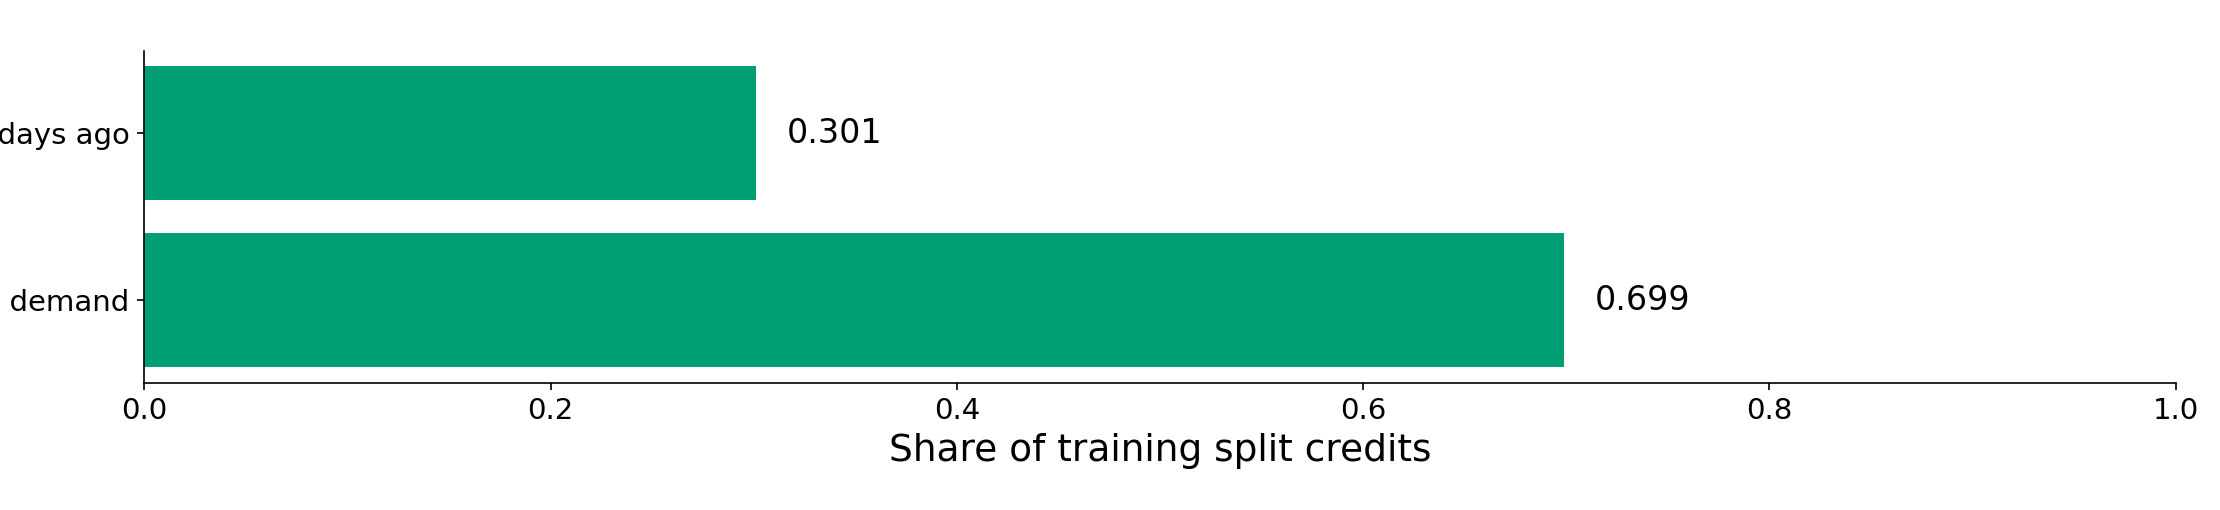

In [105]:
# Lecture code 4.19.2
(fig, aa) = canvas()
imp = forest.feature_importances_
aa[0].barh(['Yesterday’s demand', 'Demand two days ago'], imp, color=COL['Forest'])
aa[0].set(xlabel='Share of training split credits', xlim=(0, 1))
for (j, v) in enumerate(imp):
    aa[0].text(v + 0.015, j, f'{v:.3f}', va='center', fontsize=16)
save(fig, 'ex19_split_importance', 'Importance is computed from the fitted forest, not assumed', 'Classroom synthetic demand; training-fit importance', [24])

### 4.19.3 — Read before running

Retain the calculated values of this example so they can be compared with the worked steps and exported tables.

In [106]:
# Lecture code 4.19.3
worked_values['split_importance'] = {'features': features, 'shares': imp.tolist()}
display(worked_values['split_importance'])

{'features': ['lag_demand', 'lag_demand_2'],
 'shares': [0.6989118908348021, 0.3010881091651979]}

### 4.19.4 — Read before running

Put the calculated values in a labeled table. The table is an output of the current run, not a manually typed performance claim.

In [107]:
# Lecture code 4.19.4
pd.DataFrame({'feature': features, 'importance': imp}).to_csv(OUT / 'split_importance.csv', index=False)

### 4.19.5 — Read before running

Fit the classroom forest with the stated preset controls. Bootstrap rows and the one-candidate feature setting provide deliberate fitting variation.

In [108]:
# Lecture code 4.19.5
unsplit_forest = RandomForestRegressor(n_estimators=3, min_samples_split=200, random_state=417, n_jobs=1).fit(X, y)

### 4.19.6 — Read before running

Retain the calculated values of this example so they can be compared with the worked steps and exported tables.

In [109]:
# Lecture code 4.19.6
worked_values['no_effective_splits'] = {'training_rows': len(train), 'min_samples_split': 200, 'importance': unsplit_forest.feature_importances_.tolist()}
display(worked_values['no_effective_splits'])

{'training_rows': 124, 'min_samples_split': 200, 'importance': [0.0, 0.0]}

### 4.19.7 — Read before running

Check the stated mathematical or timing property for this worked example. A failed check is a reason to inspect the inputs or calculation.

In [110]:
# Lecture code 4.19.7
assert np.allclose(unsplit_forest.feature_importances_, 0)

<a id="example-4-20"></a>
## 4.20 — Shuffle one validation input at a time

Permutation importance reevaluates a fixed model after an input is rearranged.



**Work through the example**
1. Keep the trained classroom forest and all 27 validation outcomes fixed. Its unshuffled validation RMSE is about 23.33.
2. Rearrange one input column, leaving its values intact but changing their row alignment. The left panel displays a five-row illustration, not all evaluation rows.
3. Repeat twenty rearrangements per input over the full validation block. Mean RMSE is approximately 32.72 for the one-day lag shuffle and 26.27 for the two-day lag shuffle.
4. Compare those errors with the same unshuffled value. The increases are approximately 9.39 and 2.93 demand units; these are development diagnostics.

### 4.20.1 — Read before running

Calculate or set `base` for this example. Keep the trained classroom forest and all 27 validation outcomes fixed. Its unshuffled validation RMSE is about 23.33. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [111]:
# Lecture code 4.20.1
base = rmse(val.demand, forest.predict(val[features]))

### 4.20.2 — Read before running

Calculate or set `permuted` for this example. Rearrange one input column, leaving its values intact but changing their row alignment. The left panel displays a five-row illustration, not all evaluation rows. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [112]:
# Lecture code 4.20.2
permuted = []

### 4.20.3 — Read before running

Calculate or set `rng` for this example. Repeat twenty rearrangements per input over the full validation block. Mean RMSE is approximately 32.72 for the one-day lag shuffle and 26.27 for the two-day lag shuffle. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [113]:
# Lecture code 4.20.3
rng = np.random.default_rng(417)

### 4.20.4 — Read before running

Hold the model and validation outcomes fixed. Repeatedly rearrange one input column, predict again and record RMSE.

In [114]:
# Lecture code 4.20.4
for feature in features:
    vals = []
    for k in range(20):
        changed = val[features].copy()
        changed[feature] = rng.permutation(changed[feature].values)
        vals.append(rmse(val.demand, forest.predict(changed)))
    permuted.append(dict(feature=feature, baseline_RMSE=base, permuted_mean_RMSE=float(np.mean(vals)), increase=float(np.mean(vals) - base), shuffle_std=float(np.std(vals, ddof=1))))

### 4.20.5 — Read before running

Put the calculated values in a labeled table. The table is an output of the current run, not a manually typed performance claim.

In [115]:
# Lecture code 4.20.5
pd.DataFrame(permuted).to_csv(OUT / 'permutation_importance.csv', index=False)

### 4.20.6 — Read before running

Plot the values or fitted rule computed above. Compare those errors with the same unshuffled value. The increases are approximately 9.39 and 2.93 demand units; these are development diagnostics. The saved image is the same figure referenced by Example 4.20 in the notes and slides.

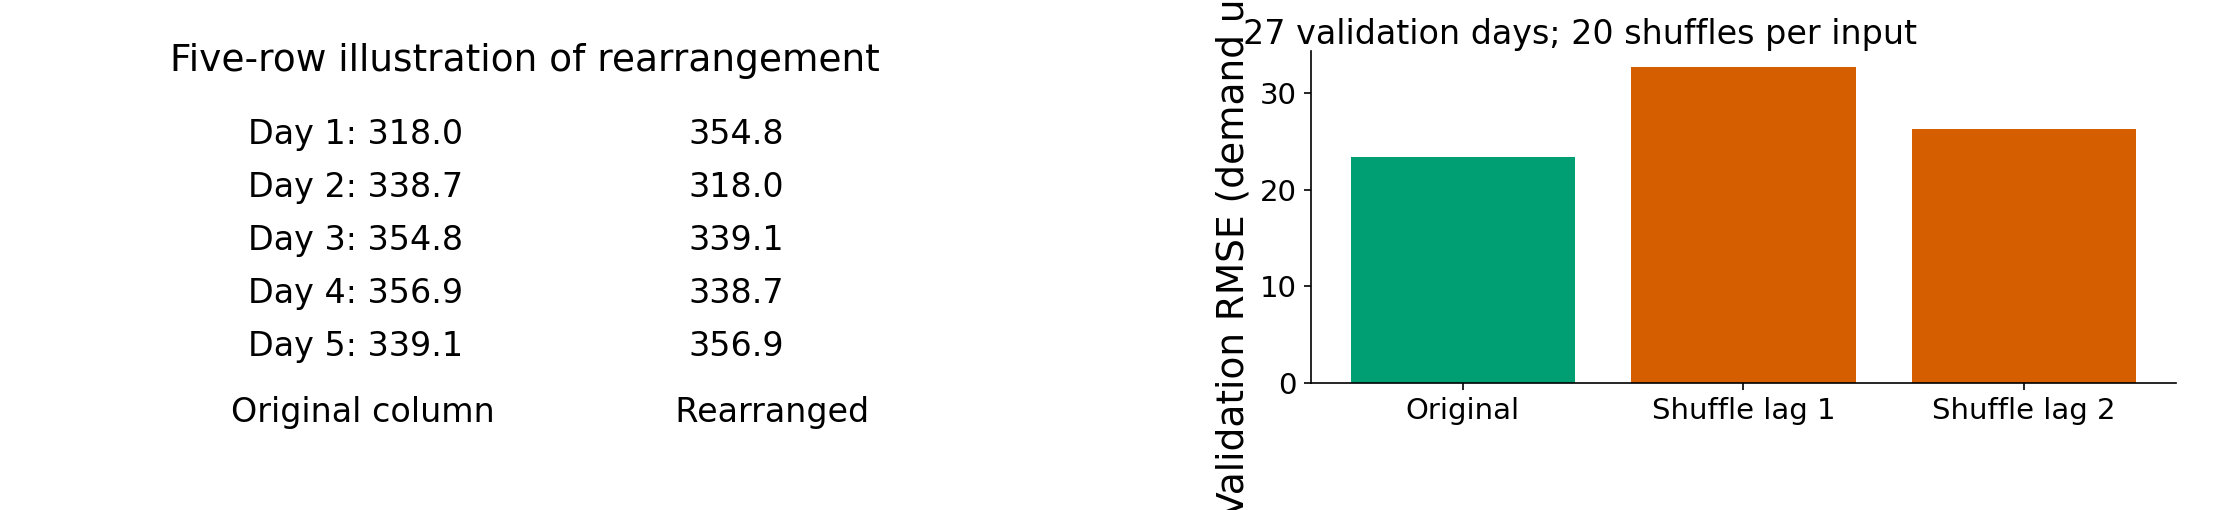

In [116]:
# Lecture code 4.20.6
(fig, aa) = canvas(2)
orig = val.lag_demand.values[:5]
shuffled = orig[[2, 0, 4, 1, 3]]
aa[0].axis('off')
aa[0].text(0.03, 0.94, 'Five-row illustration of rearrangement', fontsize=18)
for (j, (v, w)) in enumerate(zip(orig, shuffled)):
    aa[0].text(0.12, 0.72 - j * 0.16, f'Day {j + 1}: {v:.1f}', fontsize=16)
    aa[0].text(0.63, 0.72 - j * 0.16, f'{w:.1f}', fontsize=16)
aa[0].text(0.1, -0.12, 'Original column                 Rearranged', fontsize=16)
aa[1].bar(['Original', 'Shuffle lag 1', 'Shuffle lag 2'], [base] + [v['permuted_mean_RMSE'] for v in permuted], color=[COL['Forest'], COL['Tree'], COL['Tree']])
aa[1].set(ylabel='Validation RMSE (demand units)')
aa[1].tick_params(axis='x', labelsize=14)
fig.text(0.56, 0.965, '27 validation days; 20 shuffles per input', va='top', fontsize=16)
save(fig, 'ex20_permutation', 'Show the actual validation effect of rearranging one input', 'Classroom synthetic demand validation; model held fixed', [25])

<a id="example-4-21"></a>
## 4.21 — Trace substitute information through two columns

Related predictors can supply substitute information to a fitted model.



**Work through the example**
1. Construct twenty counter values and copy the same values into a second column. The two traces deliberately overlap.
2. Rearranging one column leaves the other column's values and ordering intact.
3. Identify exactly which information connection the perturbation breaks and which substitute remains.
4. The plot illustrates the information structure. It is not itself a measured claim about a trained model's permutation score; any such score must be computed and labeled separately.

### 4.21.1 — Read before running

Plot the values or fitted rule computed above. The plot illustrates the information structure. It is not itself a measured claim about a trained model's permutation score; any such score must be computed and labeled separately. The saved image is the same figure referenced by Example 4.21 in the notes and slides.

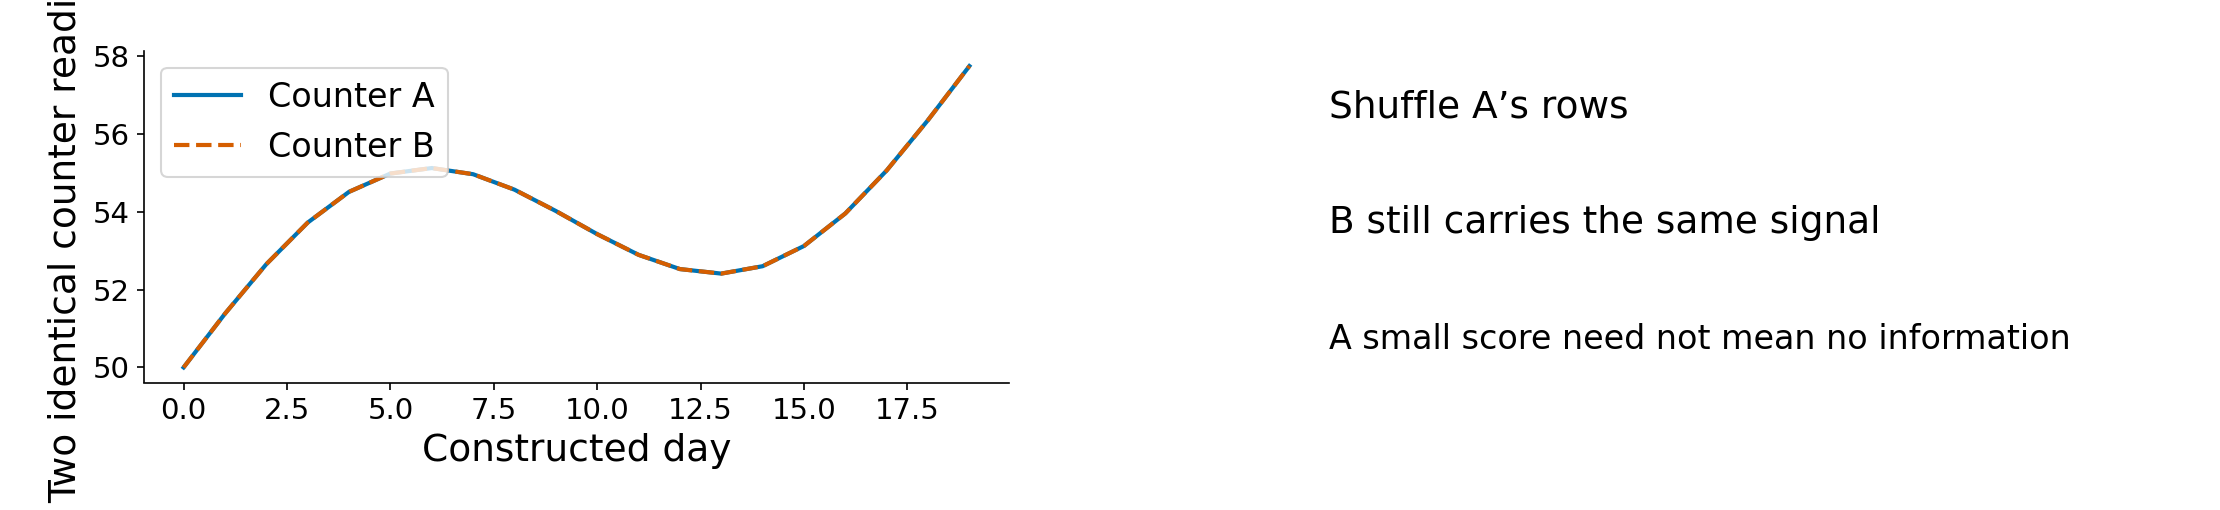

In [117]:
# Lecture code 4.21.1
(fig, aa) = canvas(2)
u = np.arange(20)
counter = 50 + 3 * np.sin(u / 3) + u * 0.4
aa[0].plot(u, counter, color=COL['Linear'], lw=2, label='Counter A')
aa[0].plot(u, counter, color=COL['Tree'], lw=2, ls='--', label='Counter B')
aa[0].set(xlabel='Constructed day', ylabel='Two identical counter readings')
aa[0].legend(loc='upper left')
aa[1].axis('off')
aa[1].text(0.02, 0.8, 'Shuffle A’s rows', fontsize=18)
aa[1].text(0.02, 0.45, 'B still carries the same signal', fontsize=18)
aa[1].text(0.02, 0.1, 'A small score need not mean no information', fontsize=16)
save(fig, 'ex21_substitute_inputs', 'Make the common-information issue explicit', 'Two deliberately identical constructed inputs', [26])

<a id="example-4-22"></a>
## 4.22 — Preserve a pipeline and compare reporting units

A pipeline applies ordered preparation and model steps; changing units can preserve tree groups.



**Work through the example**
1. Fit any learned preparation and the prediction rule using permitted earlier observations. Apply the stored procedure to later inputs.
2. Reuse the eight traffic/sales pairs. Fit once with traffic in customers, and once with traffic divided by 100, reported in hundreds of customers.
3. The learned cutoffs are 50 customers and approximately 0.5 hundreds. Queries 35 and 75 become 0.35 and 0.75.
4. Both fitted trees give predictions 26 and 66. Floating-point cutoff display can differ slightly, but the fitted group assignments and predictions agree for these cases.

### 4.22.1 — Read before running

Draw the stated mechanism with labels. This is an explicitly constructed conceptual diagram, not evidence that one model forecasts better.

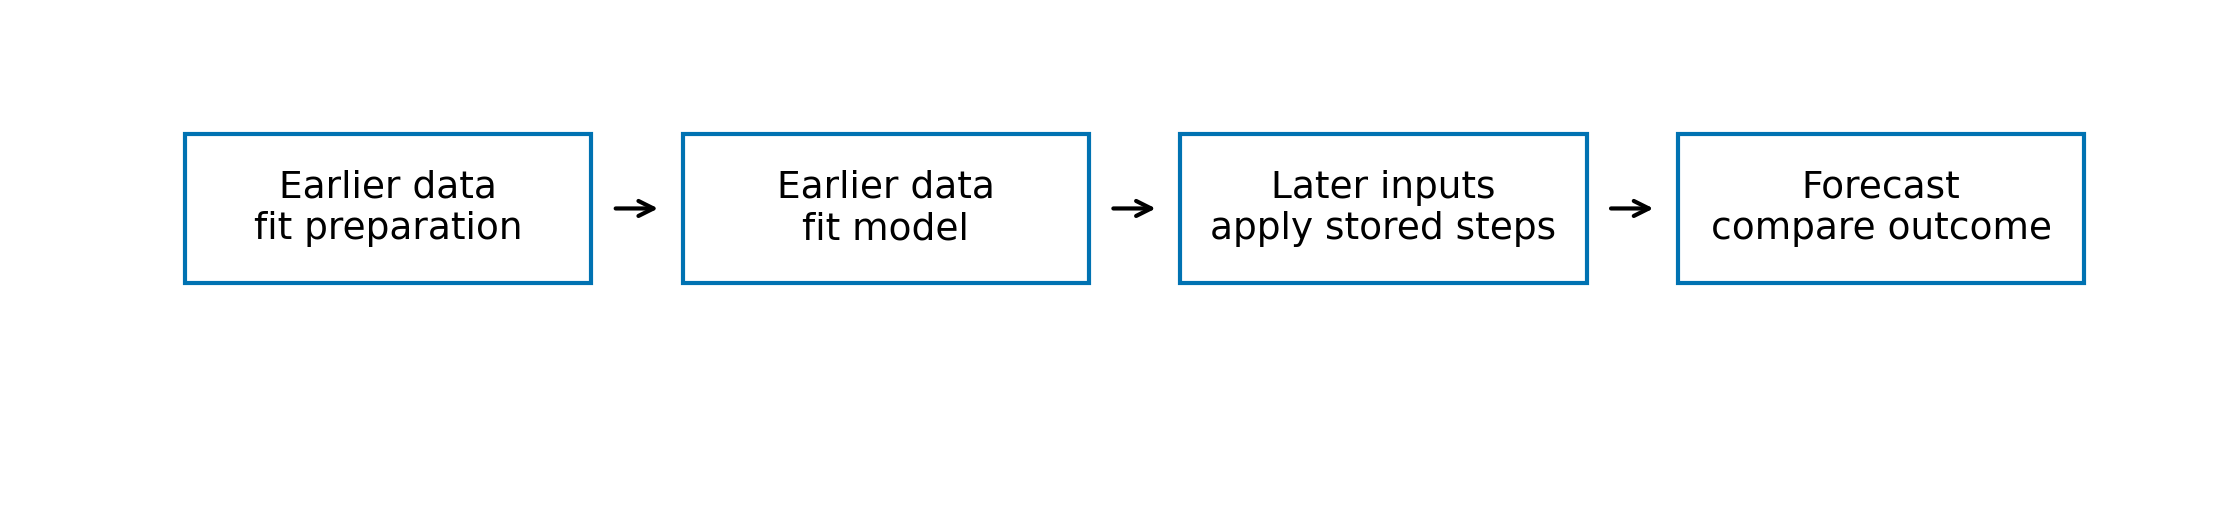

In [118]:
# Lecture code 4.22.1
flow('ex22_pipeline', ['Earlier data\nfit preparation', 'Earlier data\nfit model', 'Later inputs\napply stored steps', 'Forecast\ncompare outcome'], 'The complete fit/predict workflow', [27])

### 4.22.2 — Read before running

Change the reporting units of the same input and refit. Inspect whether the resulting leaf assignments and predictions agree.

In [119]:
# Lecture code 4.22.2
scaled_stump = DecisionTreeRegressor(max_depth=1, random_state=417).fit((traffic / 100)[:, None], sales)

### 4.22.3 — Read before running

Change the reporting units of the same input and refit. Inspect whether the resulting leaf assignments and predictions agree.

In [120]:
# Lecture code 4.22.3
assert np.allclose(stump.predict([[35], [75]]), scaled_stump.predict([[0.35], [0.75]]))

### 4.22.4 — Read before running

Change the reporting units of the same input and refit. Inspect whether the resulting leaf assignments and predictions agree.

In [121]:
# Lecture code 4.22.4
worked_values['rescaling'] = {'original_cutoff': threshold, 'scaled_cutoff': float(scaled_stump.tree_.threshold[0]), 'original_cases': [35, 75], 'scaled_cases': [0.35, 0.75], 'predictions': leaf_preds.tolist()}
display(worked_values['rescaling'])

{'original_cutoff': 50.0,
 'scaled_cutoff': 0.5000000149011612,
 'original_cases': [35, 75],
 'scaled_cases': [0.35, 0.75],
 'predictions': [26.0, 66.0]}

### 4.22.5 — Read before running

Plot the values or fitted rule computed above. Both fitted trees give predictions 26 and 66. Floating-point cutoff display can differ slightly, but the fitted group assignments and predictions agree for these cases. The saved image is the same figure referenced by Example 4.22 in the notes and slides.

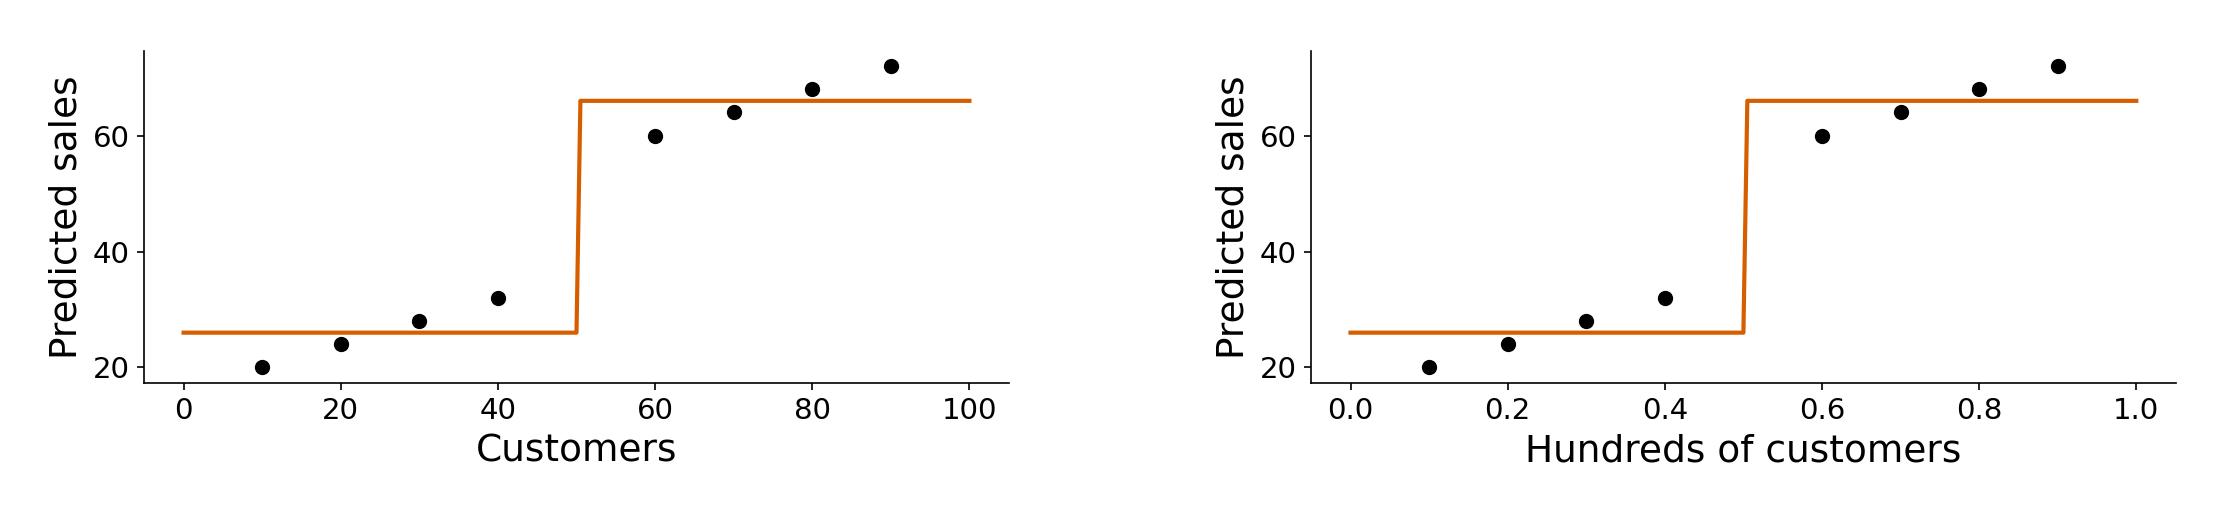

In [122]:
# Lecture code 4.22.5
(fig, aa) = canvas(2)
for (ax, scale, unit, model) in [(aa[0], 1, 'Customers', stump), (aa[1], 100, 'Hundreds of customers', scaled_stump)]:
    ax.scatter(traffic / scale, sales, color='black', s=40)
    gg = np.linspace(0, 100, 201) / scale
    ax.plot(gg, model.predict(gg[:, None]), color=COL['Tree'], lw=2)
    ax.set(xlabel=unit, ylabel='Predicted sales')
save(fig, 'ex30_rescaling', 'Different input units preserve the same partition and predictions', 'Same eight constructed traffic/sales pairs', [])

<a id="example-4-23"></a>
## 4.23 — Report validation and refitted test results

Model comparison uses the same target, dates and units, with settings chosen before final testing.



**Work through the example**
1. Compare Linear, Quadratic, Ridge, the jointly selected Tree, the preset Forest and Persistence on the same validation dates.
2. The validation RMSE values are approximately 20.62, 21.09, 20.62, 20.63, 23.33, 22.89. Linear, ridge and tree are very close; a forest win is not assumed.
3. Refit each settled learned procedure using training plus validation. Then predict the final 27 dates; persistence uses the latest observed demand directly.
4. Report the test scores without retuning: approximately 28.77, 29.11, 28.77, 30.90, 32.55, 29.12 in the same model order. These results concern this simulation, not a universal ranking.

### 4.23.1 — Read before running

Calculate or set `results` for this example. Compare Linear, Quadratic, Ridge, the jointly selected Tree, the preset Forest and Persistence on the same validation dates. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [123]:
# Lecture code 4.23.1
results = []

### 4.23.2 — Read before running

Calculate or set `development` for this example. The validation RMSE values are approximately 20.62, 21.09, 20.62, 20.63, 23.33, 22.89. Linear, ridge and tree are very close; a forest win is not assumed. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [124]:
# Lecture code 4.23.2
development = pd.concat([train, val])

### 4.23.3 — Read before running

Make a fresh copy of the settled procedure, refit it using training plus validation, and evaluate it on the untouched final dates.

In [125]:
# Lecture code 4.23.3
for (name, m) in models.items():
    final_model = clone(m).fit(development[features], development.demand)
    results.append(dict(model=name, validation_RMSE=rmse(val.demand, m.predict(val[features])), test_RMSE=rmse(test.demand, final_model.predict(test[features]))))

### 4.23.4 — Read before running

Record or display the current example's output. Report the test scores without retuning: approximately 28.77, 29.11, 28.77, 30.90, 32.55, 29.12 in the same model order. These results concern this simulation, not a universal ranking.

In [126]:
# Lecture code 4.23.4
results.append(dict(model='Persistence', validation_RMSE=rmse(val.demand, val.lag_demand), test_RMSE=rmse(test.demand, test.lag_demand)))

### 4.23.5 — Read before running

Put the calculated values in a labeled table. The table is an output of the current run, not a manually typed performance claim.

In [127]:
# Lecture code 4.23.5
comparison = pd.DataFrame(results)

### 4.23.6 — Read before running

Record or display the current example's output. Report the test scores without retuning: approximately 28.77, 29.11, 28.77, 30.90, 32.55, 29.12 in the same model order. These results concern this simulation, not a universal ranking.

In [128]:
# Lecture code 4.23.6
comparison.to_csv(OUT / 'model_comparison.csv', index=False)

### 4.23.7 — Read before running

Plot the values or fitted rule computed above. Report the test scores without retuning: approximately 28.77, 29.11, 28.77, 30.90, 32.55, 29.12 in the same model order. These results concern this simulation, not a universal ranking. The saved image is the same figure referenced by Example 4.23 in the notes and slides.

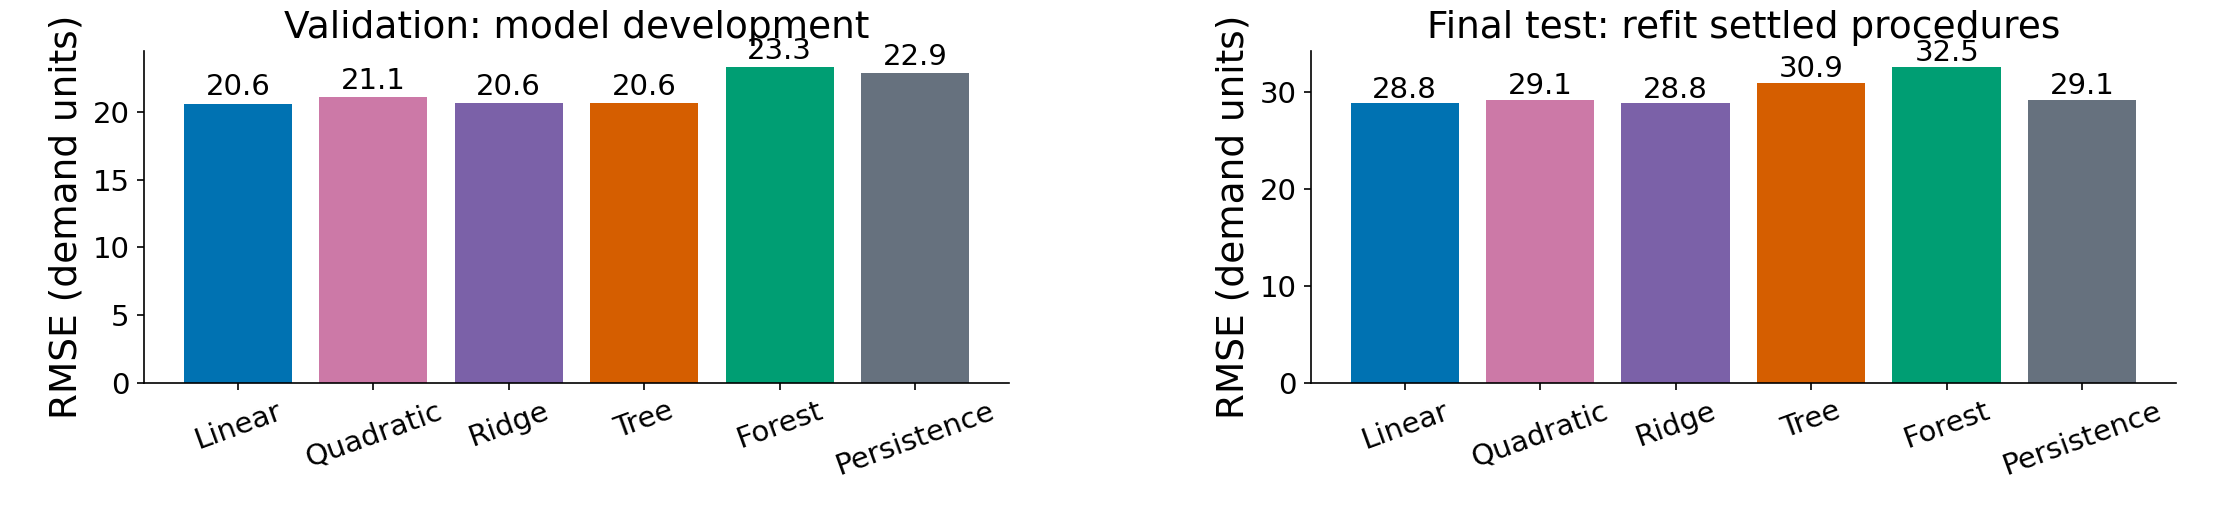

In [129]:
# Lecture code 4.23.7
(fig, aa) = canvas(2)
for (ax, col) in zip(aa, ['validation_RMSE', 'test_RMSE']):
    vals = comparison[col].values
    ax.bar(range(len(comparison)), vals, color=[COL[v] for v in comparison.model])
    ax.set(xticks=range(len(comparison)), xticklabels=comparison.model, ylabel='RMSE (demand units)')
    ax.tick_params(axis='x', labelsize=14, rotation=20)
    ax.set_title('Validation: model development' if col == 'validation_RMSE' else 'Final test: refit settled procedures', fontsize=18)
    for (j, v) in enumerate(vals):
        ax.text(j, v + 0.6, f'{v:.1f}', ha='center', fontsize=14)
save(fig, 'ex23_model_comparison', 'Report measured scores, including a simple benchmark', 'Classroom synthetic demand; same dates per evaluation block', [28])

<a id="example-4-24"></a>
## 4.24 — Refit while holding reference inputs fixed

Changing the training sample and changing the prediction case answer different questions.

A percentile is a position in ordered values. The 25th and 75th percentiles mark lower and higher positions in each training input. These constructed reference vectors stay fixed across every refit.

**Work through the example**
1. Construct low-lag and high-lag reference input pairs from the training-data range. Keep both vectors unchanged throughout the diagnostic.
2. Fit the same selected tree and preset forest on six 80-day windows ending at rows 80,90,100,110,120,124 within training history.
3. After each fit, predict the two unchanged vectors and plot each vector in its own panel.
4. Variation along a panel tracks refit sensitivity for a fixed case. A difference between panels reflects different input conditions and must not be called model instability.

### 4.24.1 — Read before running

Choose two reference input vectors once from the training-data range. These cases remain fixed across the refits.

In [130]:
# Lecture code 4.24.1
refs = pd.DataFrame([X.quantile(0.25), X.quantile(0.75)], columns=features, index=['Quiet reference', 'Busy reference'])

### 4.24.2 — Read before running

Calculate or set `endpoints` for this example. Fit the same selected tree and preset forest on six 80-day windows ending at rows 80,90,100,110,120,124 within training history. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [131]:
# Lecture code 4.24.2
endpoints = list(range(80, len(train) + 1, 10))

### 4.24.3 — Read before running

Calculate or set `endpoints` for this example. After each fit, predict the two unchanged vectors and plot each vector in its own panel. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [132]:
# Lecture code 4.24.3
endpoints = sorted(set(endpoints + [len(train)]))

### 4.24.4 — Read before running

Calculate or set `refit` for this example. After each fit, predict the two unchanged vectors and plot each vector in its own panel. Inspect the resulting object or its later printed/graphical output before changing the inputs.

In [133]:
# Lecture code 4.24.4
refit = []

### 4.24.5 — Read before running

Retain the calculated values of this example so they can be compared with the worked steps and exported tables.

In [134]:
# Lecture code 4.24.5
worked_values['reference_inputs'] = refs.to_dict('index')
display(worked_values['reference_inputs'])

{'Quiet reference': {'lag_demand': 298.925, 'lag_demand_2': 299.37},
 'Busy reference': {'lag_demand': 347.68, 'lag_demand_2': 347.68}}

### 4.24.6 — Read before running

Move an 80-day training window, refit the same model settings and query the same two reference vectors after each fit.

In [135]:
# Lecture code 4.24.6
for end in endpoints:
    xx = X.iloc[end - 80:end]
    yy = y.iloc[end - 80:end]
    mm = {'Tree': DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=best_leaf, random_state=417).fit(xx, yy), 'Forest': RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=8, max_features=1, random_state=417, n_jobs=1).fit(xx, yy)}
    for (model, m) in mm.items():
        for (case, value) in zip(refs.index, m.predict(refs)):
            refit.append(dict(training_end=end, model=model, case=case, prediction=float(value)))

### 4.24.7 — Read before running

Put the calculated values in a labeled table. The table is an output of the current run, not a manually typed performance claim.

In [136]:
# Lecture code 4.24.7
refit = pd.DataFrame(refit)

### 4.24.8 — Read before running

Record or display the current example's output. Variation along a panel tracks refit sensitivity for a fixed case. A difference between panels reflects different input conditions and must not be called model instability.

In [137]:
# Lecture code 4.24.8
refit.to_csv(OUT / 'fixed_case_refits.csv', index=False)

### 4.24.9 — Read before running

Plot the values or fitted rule computed above. Variation along a panel tracks refit sensitivity for a fixed case. A difference between panels reflects different input conditions and must not be called model instability. The saved image is the same figure referenced by Example 4.24 in the notes and slides.

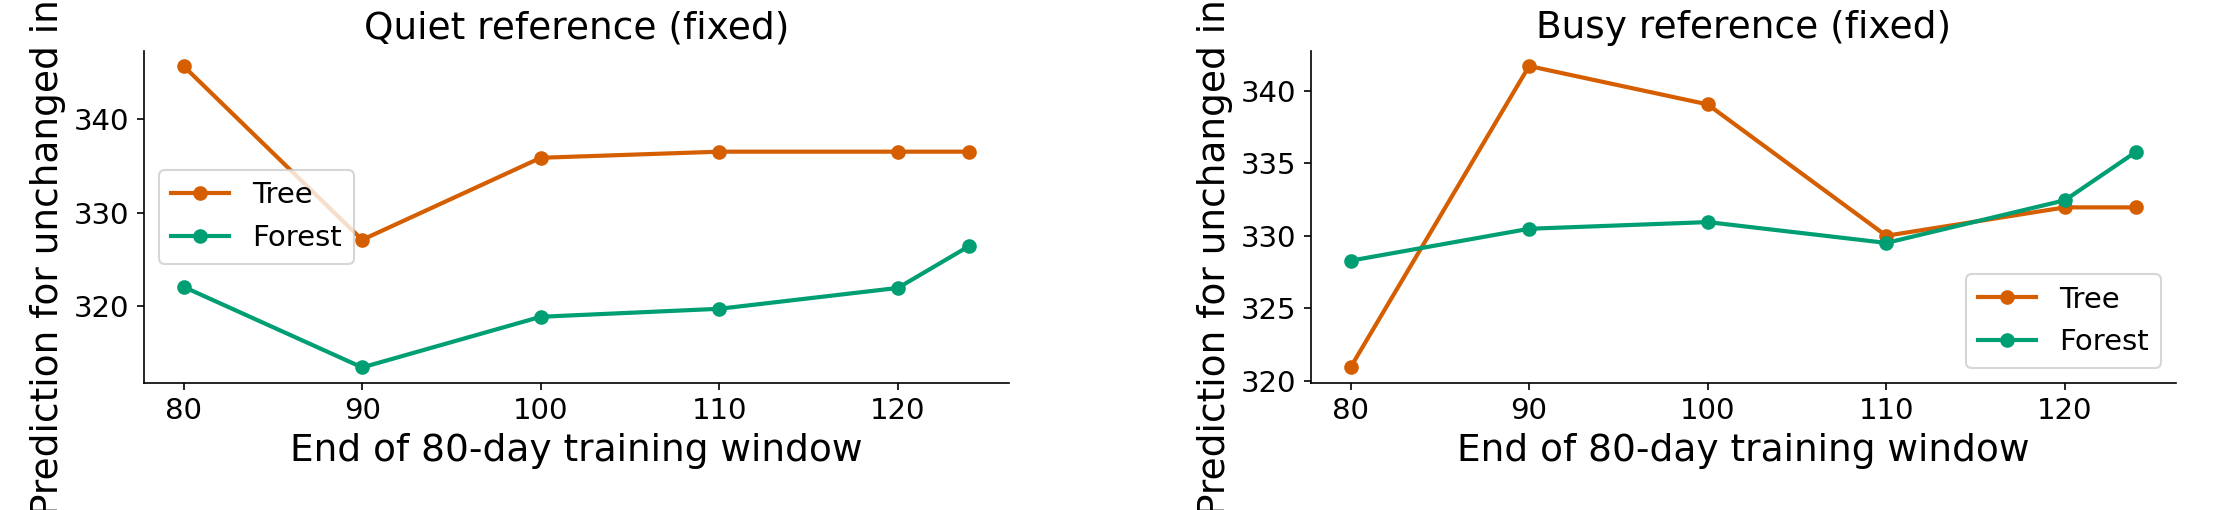

In [138]:
# Lecture code 4.24.9
(fig, aa) = canvas(2)
for (ax, case) in zip(aa, refs.index):
    for name in ['Tree', 'Forest']:
        df = refit[(refit.model == name) & (refit.case == case)]
        ax.plot(df.training_end, df.prediction, 'o-', color=COL[name], lw=2, label=name)
    ax.set(xlabel='End of 80-day training window', ylabel='Prediction for unchanged inputs')
    ax.set_title(case + ' (fixed)', fontsize=18)
    ax.legend(loc='best', fontsize=14)
save(fig, 'ex24_fixed_case_refits', 'Compare real refits on the same two input vectors', 'Classroom training history only; same algorithm seed and reference cases', [29])

<a id="example-4-25"></a>
## 4.25 — Predict beyond the observed input range

Extrapolation applies a rule outside represented input conditions.



**Work through the example**
1. Reuse the same eight traffic/sales training pairs, whose largest observed input is 90.
2. Fit the one-split tree and linear regression using only those pairs.
3. Query inputs out to 140. The tree keeps returning its right-leaf mean 66; the fitted linear rule continues its line.
4. Read the shaded region as outside the training input range. No target outcomes in that region were supplied to validate either continuation.

### 4.25.1 — Read before running

Plot the values or fitted rule computed above. Read the shaded region as outside the training input range. No target outcomes in that region were supplied to validate either continuation. The saved image is the same figure referenced by Example 4.25 in the notes and slides.

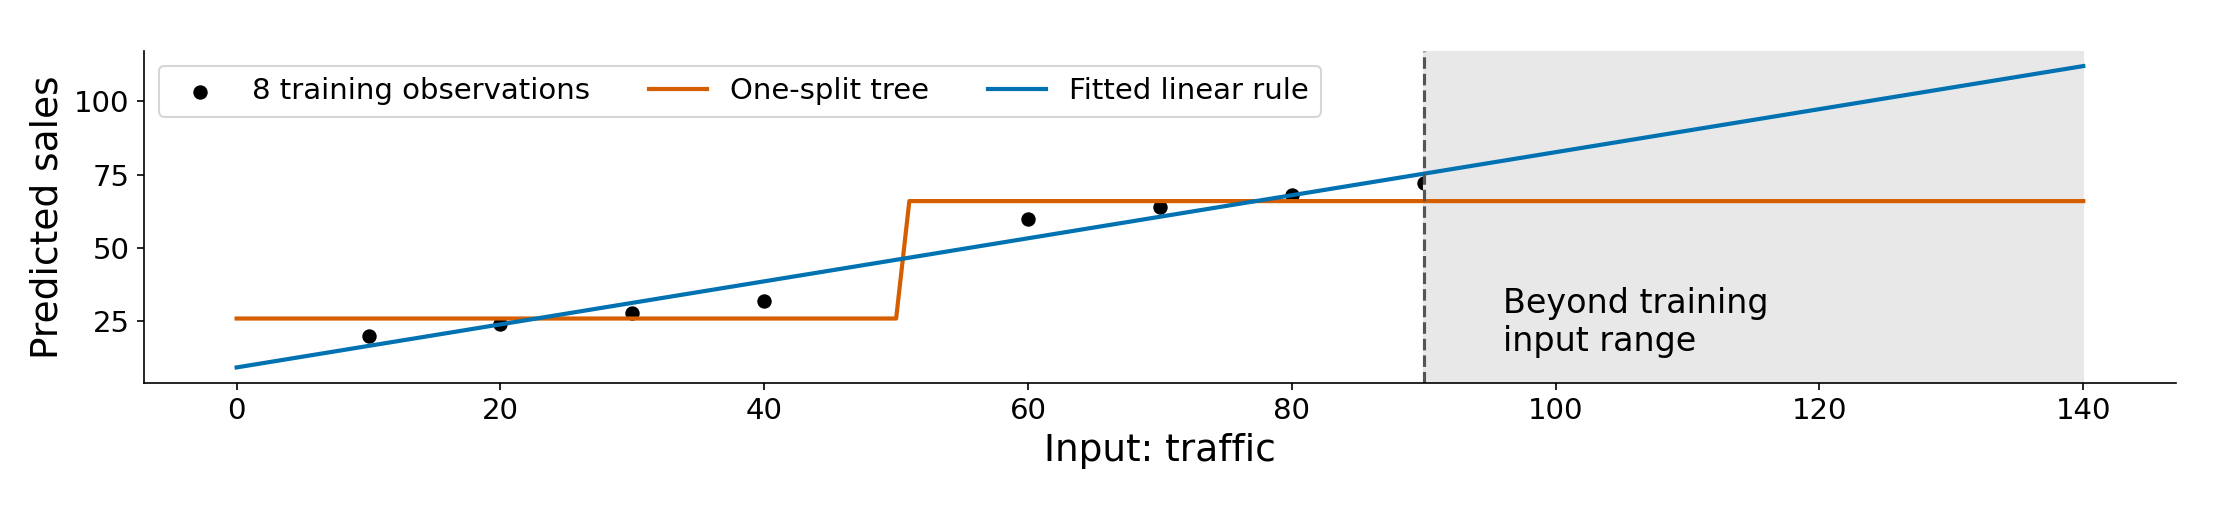

In [139]:
# Lecture code 4.25.1
(fig, aa) = canvas()
g = np.arange(0, 141)
ols = LinearRegression().fit(traffic[:, None], sales)
aa[0].scatter(traffic, sales, color='black', s=35, label='8 training observations')
aa[0].plot(g, stump.predict(g[:, None]), color=COL['Tree'], lw=2, label='One-split tree')
aa[0].plot(g, ols.predict(g[:, None]), color=COL['Linear'], lw=2, label='Fitted linear rule')
aa[0].axvspan(90, 140, color='#E8E8E8')
aa[0].axvline(90, color='#555555', ls='--')
aa[0].set(xlabel='Input: traffic', ylabel='Predicted sales')
aa[0].legend(loc='upper left', ncol=3, fontsize=14)
aa[0].text(96, 15, 'Beyond training\ninput range', fontsize=16)
save(fig, 'ex25_extrapolation', 'The tree returns a stored mean beyond observed input conditions', 'Same eight constructed training pairs; no new target outcomes', [30])

### 4.25.2 — Read before running

Load the shared example-number index used by the notes, slides and notebook. This is a teaching cross-reference, not another dataset or model.

In [140]:
# Lecture code 4.25.2
catalog = json.loads((NOTEBOOK_ROOT / 'resources/Lecture_04_examples.json').read_text())

### 4.25.3 — Read before running

Attach each public example ID and its current slide pages to the generated figure record. This connects the same computed image across the three teaching materials without changing any fitted prediction.

In [141]:
# Lecture code 4.25.3
for rec in records:
    case = next((e for e in catalog if rec['id'] in e['figures']), None)
    if case:
        rec['example_id'] = case['id']
        rec['example_title'] = case['title']
        current = json.loads((NOTEBOOK_ROOT / 'resources/Lecture_04_figure_pages.json').read_text())
        rec['source_topic_slides'] = rec['slides']
        rec['slides'] = [r['slide'] for r in current if r.get('code_figure', {}).get('id') == rec['id']]

### 4.25.4 — Read before running

Collect this run's data source, model settings and evaluation results so a reader can reproduce the comparison. These records do not select a model from test performance.

In [142]:
# Lecture code 4.25.4
provenance = dict(data='Classroom synthetic demand, seed 417; not real market data', original_data='Coding_Notes/data/Lecture_04/business_demand.csv', original_instructor='Classroom worked examples', rows=len(data), usable_rows=len(frame), training_rows=len(train), validation_rows=len(val), test_rows=len(test), best_depth=best_depth, best_leaf=best_leaf, best_ridge_alpha=best_alpha, forest_settings=forest.get_params(), changes_from_classroom_key='Expanded depth 1..8 and leaf-size grid 1,2,4,8,16 chosen jointly; min leaf=2 only in the one-control depth illustration; explicit max_features=1 for forest. Settings chosen before test reporting.', test_fit='Refit each settled candidate on training plus validation, then predict final test', model_comparison=results, permutation=permuted, figures=records)

### 4.25.5 — Read before running

Save the calculated hand-example values, including leaf means, indicator values and tree averages, to the current outputs folder.

In [143]:
# Lecture code 4.25.5
(OUT / 'worked_values.json').write_text(json.dumps(worked_values, indent=2) + '\n')

3005

### 4.25.6 — Read before running

Save the actual three candidate-column draws from Example 4.14, using node identifiers 1, 2 and 3.

In [144]:
# Lecture code 4.25.6
pd.DataFrame(draws, columns=['first_candidate', 'second_candidate'], index=np.arange(1, len(draws) + 1)).to_csv(OUT / 'candidate_feature_draws.csv', index_label='node')

### 4.25.7 — Read before running

Save the current lecture run's settings and measured results. Interpret each score with its recorded training and evaluation periods.

In [145]:
# Lecture code 4.25.7
(OUT / 'run_results.json').write_text(json.dumps(provenance, indent=2, default=str) + '\n')

17681

### 4.25.8 — Read before running

Save the generated-figure index, including the shared example numbers and current slide pages. The index lets the instructor check which output produced a displayed figure.

In [146]:
# Lecture code 4.25.8
(GRAPH / 'figure_manifest.json').write_text(json.dumps(records, indent=2) + '\n')

14347

### 4.25.9 — Read before running

Display the measured model comparison and the selected validation settings. The reported source remains the local classroom simulation.

In [147]:
# Lecture code 4.25.9
print(comparison.to_string(index=False))

      model  validation_RMSE  test_RMSE
     Linear        20.617411  28.765323
  Quadratic        21.093190  29.113049
      Ridge        20.623769  28.768987
       Tree        20.625749  30.895303
     Forest        23.331014  32.549563
Persistence        22.886943  29.121083


### 4.25.10 — Read before running

Record or display the current example's output. Read the shaded region as outside the training input range. No target outcomes in that region were supplied to validate either continuation.

In [148]:
# Lecture code 4.25.10
print('Chosen depth', best_depth, 'Ridge alpha', best_alpha)

Chosen depth 5 Ridge alpha 0.1


### 4.25.11 — Read before running

Record or display the current example's output. Read the shaded region as outside the training input range. No target outcomes in that region were supplied to validate either continuation.

In [149]:
# Lecture code 4.25.11
print('Generated', len(records), 'figures. Data are synthetic classroom examples.')

Generated 31 figures. Data are synthetic classroom examples.
